# 04 - Validação e experiências de modelação

## Objetivo e estrutura

Este notebook avalia um modelo de regressão Random Forest que estima, a partir das características radiómicas dos contornos dos radiologistas, as classificações de malignidade atribuídas pelos leitores. As previsões contínuas são convertidas em classes através de pontos de corte. Os alvos são avaliações de suspeição dos leitores, não diagnósticos confirmados nem probabilidades de cancro.

O notebook tem duas partes. A primeira trata o problema original de 5 classes (classificações 1 a 5): experiências com o número de características, com variáveis-alvo alternativas e com os hiperparâmetros, seguidas da validação, da auditoria de equidade e da interpretabilidade do modelo escolhido. A segunda reutiliza o mesmo regressor como ferramenta de triagem em 3 classes (baixo risco, indeterminado e alto risco), com pontos de corte orientados pela sensibilidade da classe de alto risco; esta parte inclui a validação, a equidade por subgrupo, as curvas ROC, o reajuste final, uma árvore simplificada para leitura das variáveis e uma experiência sobre o efeito do desequilíbrio de classes.

A avaliação segue uma divisão fixa por paciente; as etapas de ajuste, validação e comparação de experiências são descritas nas secções seguintes.

## Protocolo principal: holdout por paciente

Cada paciente pertence a uma única partição do manifesto fixo: ajuste, limiares, seleção ou validação. Durante a seleção e a avaliação, o modelo e o pré-processamento aprendido são ajustados apenas com os pacientes de ajuste; o reajuste final é descrito abaixo. Os pontos de corte calibrados são determinados a partir das previsões desse modelo para os pacientes da partição de limiares, que não foram usados no ajuste. A partição de seleção serve para comparar estratégias e experiências com os pontos de corte já definidos; a validação é usada uma única vez por configuração escolhida.

O notebook segue esta ordem: primeiro, as experiências com o número de características, as variáveis-alvo alternativas e os hiperparâmetros, que usam apenas os pacientes de ajuste, limiares e seleção; depois, a avaliação única na validação do modelo de 5 classes com as escolhas dessas experiências (`SELECTED_FIT_SETTINGS`), seguida das auditorias de equidade e interpretabilidade; por fim, o modelo de triagem em 3 classes, escolhido nos pacientes de seleção e avaliado uma única vez na validação, seguido da auditoria por subgrupo, das curvas ROC, do reajuste final, da árvore simplificada e da experiência com o desequilíbrio de classes. Reinicie o kernel depois de atualizar os módulos do projeto.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "src/lung_project").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter from project/ or project/notebooks/")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import hashlib
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from lung_project.ct import CropRules
from lung_project.dataset import eligible_feature_cohort, saved_holdout_split
from lung_project.evaluation import calculate_metrics, validate_training_table
from lung_project.experiments import (
    save_holdout_run,
    snapshot_inputs,
    write_json,
    new_run_path,
    run_feature_count_sweep,
    run_hyperparameter_sweep,
    best_hyperparameters,
    run_target_comparisons,
    rating_target_mapping,
    plot_contour_comparisons,
)
from lung_project.fairness import fairness_audit
from lung_project.interpretability import interpretability_audit
from lung_project.features import contour_radiomics_extractor, contour_radiomics_configuration
from lung_project.labels import characteristic_amplitude_summary
from lung_project.modeling_feng import evaluate_contour_holdout
from lung_project.paths import CONTOUR_HOLDOUT_SPLIT_PATH, require_file
from lung_project.prepared import (
    read_contour_features,
    contour_feature_table_path,
    radiomics_columns,
    contour_feature_metadata,
)
from lung_project.scan_pipeline import rules_id
from sklearn.metrics import ConfusionMatrixDisplay


## Configuração e definição dos rótulos

Mantêm-se as variáveis-alvo e as associações de leitores revistas no notebook 01. O ficheiro `config/contour_holdout.json` define a semente e as frações de pacientes: 20% para validação, 15% para calibração dos limiares e 20% dos restantes pacientes para seleção. Ficam cerca de 52% dos pacientes para ajuste. A divisão procura equilibrar, dentro de cada conjunto de dados, as distribuições das classificações e o número de nódulos; como cada paciente permanece inteiro numa única partição, as proporções exatas de nódulos podem variar.

Antes do reajuste final, as partições têm os seguintes papéis:

| Partição | Utilização | Não usada para |
|---|---|---|
| ajuste (`fitting`) | imputação, filtro de correlação, informação mútua, normalização, PCA e RandomForest | estimar o desempenho fora da amostra |
| limiares (`threshold`) | otimizar os pontos de corte com previsões de um modelo que nunca viu estes pacientes | ajustar o regressor ou estimar o desempenho final |
| seleção (`selection`) | comparar estratégias e experiências com limiares fixos | ajustar o regressor ou otimizar os limiares |
| validação (`validation`) | avaliar a configuração escolhida | selecionar essa configuração ou os seus limiares |

A configuração base (`FIT_SETTINGS`) usa RandomForest com 500 árvores, tamanho mínimo das folhas igual a 5, fração de características igual a 0,3 e profundidade máxima de 20; a experiência com hiperparâmetros pode substituir o número de árvores, a profundidade máxima e o tamanho mínimo das folhas antes da validação. As estratégias `default` (pontos médios das classes) e `calibrated` usam o mesmo modelo ajustado, pelo que diferem apenas nos pontos de corte; a vencedora é a de maior QWK agregada nos pacientes de seleção. Os limiares `calibrated` maximizam a QWK sobre as previsões dos pacientes de limiares, através de uma pesquisa determinística por coordenadas. Não se usam previsões sobre os próprios dados de treino, que estariam enviesadas para os rótulos, nem previsões out-of-bag, que excluem nódulos isolados e não pacientes completos.

Depois da validação, ajusta-se de novo o modelo vencedor em todos os pacientes exceto os de limiares (ajuste, seleção e validação) e voltam a otimizar-se os limiares nos mesmos pacientes de limiares, com as previsões deste modelo final. A validação estima este procedimento; o modelo final não tem uma avaliação independente própria. Registam-se todas as definições, atribuições, previsões, modelos e limiares.

Em cada ajuste, a imputação pela mediana, o filtro de correlação de Pearson, a seleção por informação mútua, a normalização, o PCA e o modelo são ajustados apenas nas linhas de treino. Os parâmetros do filtro, o número de características e a variância explicada pelo PCA são definidos abaixo. Por predefinição, usam-se pesos de amostra equilibrados por classe, mantendo o multiplicador aplicado ao LNDb. Se o SMOTE for ativado, a imputação e a normalização são ajustadas nos dados originais da partição de ajuste antes da reamostragem de cada conjunto de dados; as etapas seguintes são ajustadas com os dados reamostrados. Nas restantes partições, aplicam-se as transformações já ajustadas, sem novo ajuste ou reamostragem.

A seleção da configuração e a calibração dos limiares usam, por predefinição, dados agregados de LIDC e LNDb. A inferência para a competição é feita no notebook 05.

`TRAINING_TARGET = "mean_rating"` ajusta o regressor à média não arredondada dos leitores retidos (`malignancy_mean`): classificações 2 e 3 ensinam 2,5. O agrupamento já guarda esta média e o rótulo inteiro `malignancy_target = floor(mean + 0.5)`. O equilíbrio de classes e a seleção por informação mútua usam o rótulo inteiro; a calibração dos limiares e todas as métricas também usam esse rótulo. Com SMOTE, a média é interpolada entre vizinhos da mesma classe e entra no cálculo das distâncias, como no notebook 05. `"label"` permite reproduzir o treino anterior.


In [2]:
TRAINING_TARGET = "mean_rating"  # Unrounded reader mean; "label" reproduces earlier runs.
lndb_weight = 4.0  # LNDb multiplier; LIDC stays 1, alongside balanced rating weights.
INCLUDE_CHARACTERISTICS = False  # Add the eight aggregated reader ratings as predictors.
THRESHOLD_OBJECTIVE = "qwk"  # "qwk": QWK only; "leaderboard": balanced accuracy + macro F1 + QWK - MAE.
ROI_DEFINITION = "reader_union"
RADIOMICS_PATH = require_file(PROJECT_ROOT / "config/radiomics.yaml")
CROP_CONFIG_PATH = require_file(PROJECT_ROOT / "config/scan_processing.json")
radiomics_bytes = RADIOMICS_PATH.read_bytes()
radiomics_sha256 = hashlib.sha256(radiomics_bytes).hexdigest()
configuration = contour_radiomics_configuration(RADIOMICS_PATH)
RUN_DIR = new_run_path(
    PROJECT_ROOT,
    f"radiomics_contours_holdout_{configuration['settings_id'][:12]}",
    lndb_weight=lndb_weight,
    tags=[
        "leaderboardthresholds" if THRESHOLD_OBJECTIVE == "leaderboard" else "",
        "meantarget" if TRAINING_TARGET == "mean_rating" else "",
    ],
)
RUN_NAME = RUN_DIR.name
SPLIT_PATH = PROJECT_ROOT / "outputs/reports" / CONTOUR_HOLDOUT_SPLIT_PATH.name
SPLIT_CONFIG_PATH = require_file(PROJECT_ROOT / "config/contour_holdout.json")
SPLIT_SETTINGS = json.loads(SPLIT_CONFIG_PATH.read_text())
CALIBRATE_THRESHOLDS_LNDB_ONLY = False  # Retain pooled threshold fitting for contour evaluation.
N_ESTIMATORS = 500
N_JOBS = -1
N_BOOTSTRAP = 2000  # Patient resamples for confidence intervals.
MODEL_NAMES = ("RandomForest",)
MODEL_SETTINGS = {"min_samples_leaf": 5, "max_features": 0.3, "max_depth": 20}
THRESHOLD_STRATEGIES = ("default", "calibrated")
CORR_THRESHOLD = 0.85
INFO_GAIN_K = 200
PCA_VARIANCE = 0.95
USE_SMOTE = False  # False uses balanced rating weights and preserves the LNDb multiplier.
FIT_SETTINGS = {
    **MODEL_SETTINGS,
    "n_estimators": N_ESTIMATORS,
    "n_jobs": N_JOBS,
    "lndb_weight": lndb_weight,
    "use_smote": USE_SMOTE,
    "training_target": TRAINING_TARGET,
    "corr_threshold": CORR_THRESHOLD,
    "info_gain_k": INFO_GAIN_K,
    "pca_variance": PCA_VARIANCE,
}
# Alternatives compared one at a time on selection patients; the best value of each
# replaces the FIT_SETTINGS value in SELECTED_FIT_SETTINGS.
HYPERPARAMETER_VALUES = {
    "n_estimators": (250, 750),
    "max_depth": (10, None),
    "min_samples_leaf": (2, 10),
}
EVALUATION_SETTINGS = {
    "selection_dataset": "pooled",
    "model_names": MODEL_NAMES,
    "lndb_only": CALIBRATE_THRESHOLDS_LNDB_ONLY,
    "threshold_strategies": THRESHOLD_STRATEGIES,
    "threshold_objective": THRESHOLD_OBJECTIVE,
}


## Carregamento e verificação dos dados extraídos

Leem-se, através do registo de etapas, as tabelas de características dos contornos do LIDC e do LNDb de treino. Verificam-se o esquema dos preditores, a configuração radiómica, as regras dos recortes, a definição da região de interesse (ROI) como união dos contornos dos leitores e a integridade das tabelas e dos dados de origem. Os identificadores, rótulos, metadados geométricos dos exames e metadados da revisão não são usados como preditores; as características radiómicas de forma do contorno fazem parte dos preditores.

`INCLUDE_CHARACTERISTICS=True` acrescenta oito características agregadas dos leitores, identificadas pelas colunas `characteristic_*`. Por omissão, a opção está desativada (`False`) e usam-se apenas características radiómicas. As médias, amplitudes e listas das avaliações, a malignidade e os metadados da revisão não são incluídos como preditores. As divergências nas características são reportadas, mas não alteram a elegibilidade. Calcificação e estrutura interna são códigos categóricos; as médias arredondadas dessas categorias não correspondem necessariamente a uma escala ordinal. Como os candidatos de teste do LNDb não incluem características dos leitores, ativar esta opção avalia um modelo assistido por anotações, não diretamente aplicável à competição. Os valores em falta são imputados apenas com base nos dados de ajuste.


In [3]:
tables = {subset: read_contour_features(subset) for subset in ("lidc", "lndb_train")}
lidc, lndb_train = (tables[name] for name in ("lidc", "lndb_train"))
if any(set(radiomics_columns(table)) != set(radiomics_columns(lidc)) for table in tables.values()):
    raise ValueError("Training and test radiomics predictor schemas differ")
raw_training = pd.concat([lidc, lndb_train], ignore_index=True, sort=False)

expected_signature = {
    "rules_id": rules_id(CropRules.from_json(CROP_CONFIG_PATH), "reader_union"),
    "roi_definition": ROI_DEFINITION,
}
feature_cache_metadata = {}
for subset, table in tables.items():
    metadata = contour_feature_metadata(subset)
    if "context" in metadata:
        # Extraction runtime belongs to the saved features, not this modeling machine.
        if metadata["context"]["settings_id"] != configuration["settings_id"]:
            raise ValueError(f"{subset}: radiomics settings changed; rerun notebook 03")
        if not table.radiomics_settings_id.eq(configuration["settings_id"]).all():
            raise ValueError(f"{subset}: radiomics settings ID differs from this run")
        feature_cache_metadata[subset] = metadata
    elif not table.radiomics_config_sha256.eq(radiomics_sha256).all():
        raise ValueError(f"{subset}: radiomics_config_sha256 differs; rerun notebook 03")
    for column, expected in expected_signature.items():
        if table[column].isna().any() or not table[column].eq(expected).all():
            raise ValueError(
                f"{subset}: saved {column} values {table[column].unique().tolist()} "
                f"differ from current code/configuration {expected!r}. "
                "Restart the kernels for notebooks 02, 03, and 04, then Run All in that order. "
                "A running kernel may still have older project modules loaded."
            )
display(
    pd.DataFrame(
        [
            {
                "subset": subset,
                "rows": len(table),
                "successfully_extracted": int(table.extraction_status.eq("ok").sum()),
            }
            for subset, table in tables.items()
        ]
    )
)

print("Reader characteristic amplitude counts (information only):")
print(characteristic_amplitude_summary(tables).to_string(index=False))


/home/rera/aulas/31c/labiacd/lung/project/src/lung_project/prepared.py:889: DtypeWarning: Columns (122: error) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(


/home/rera/aulas/31c/labiacd/lung/project/src/lung_project/prepared.py:889: DtypeWarning: Columns (58: rating_review_action) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(


/home/rera/aulas/31c/labiacd/lung/project/src/lung_project/prepared.py:889: DtypeWarning: Columns (122: error) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(


/home/rera/aulas/31c/labiacd/lung/project/src/lung_project/prepared.py:889: DtypeWarning: Columns (58: rating_review_action) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(


,subset,rows,successfully_extracted
0,lidc,2690,2561
1,lndb_train,1219,712


Reader characteristic amplitude counts (information only):
   dataset     characteristic  nodules  known_amplitude  amplitude_ge_3
      lidc           subtlety     2690             2690             230
      lidc internal_structure     2690             2690              17
      lidc      calcification     2690             2690             144
      lidc         sphericity     2690             2690             119
      lidc             margin     2690             2690             258
      lidc         lobulation     2690             2690             226
      lidc        spiculation     2690             2690             194
      lidc            texture     2690             2690             141
lndb_train           subtlety      768              768               9
lndb_train internal_structure      768              768               4
lndb_train      calcification      768              768              20
lndb_train         sphericity      768              768              11
lndb_

## Fixação da divisão holdout por paciente

Cria-se o manifesto holdout na primeira execução e reutiliza-se nas seguintes. Esta divisão fixa mantém os mesmos pacientes nos grupos de ajuste, limiares, seleção e validação entre experiências, evitando sobreposição de pacientes e permitindo comparações consistentes. O manifesto guarda a coorte de referência completa, com rótulos e identidades, e atribui cada paciente a exatamente uma partição. A leitura verifica o hash, a pertença de todos os nódulos de cada paciente à mesma partição, a ausência de sobreposição entre partições e a presença de todos os conjuntos de dados em cada partição. Cada candidato de referência tem de manter o rótulo e a identidade, e ter sido extraído com sucesso. Os candidatos elegíveis adicionais ficam fora das quatro partições.

Alterações nas definições exigem um novo caminho para o manifesto e um novo nome para a experiência. Antes de interpretar os resultados, verifique as contagens apresentadas, incluindo a representação de pacientes com classificações raras.

,partition,dataset,patients,nodules,rating_1,rating_2,rating_3,rating_4,rating_5,rating_1_patients,rating_2_patients,rating_3_patients,rating_4_patients,rating_5_patients
0,fitting,lidc,439,1332,150,313,613,192,64,104,194,291,139,56
1,fitting,lndb,108,371,102,119,105,36,9,61,67,60,28,7
2,threshold,lidc,127,384,43,90,177,56,18,29,48,88,37,17
3,threshold,lndb,31,106,29,34,30,10,3,14,17,15,7,3
4,selection,lidc,110,333,38,78,153,48,16,18,48,71,32,14
5,selection,lndb,27,92,25,30,26,9,2,13,17,13,6,2
6,validation,lidc,169,512,58,120,235,74,25,44,78,101,49,19
7,validation,lndb,41,143,39,46,40,14,4,21,29,21,14,4


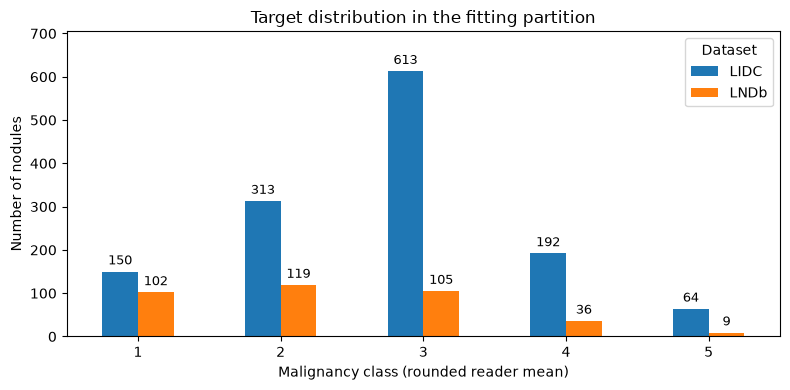

Additional eligible candidates outside the reference cohort: 0


In [4]:
eligible_training = eligible_feature_cohort(raw_training)
shared_split, training = saved_holdout_split(raw_training, path=SPLIT_PATH, settings=SPLIT_SETTINGS)
feature_columns = validate_training_table(training, include_characteristics=INCLUDE_CHARACTERISTICS)
split_settings = shared_split["settings"]
SEED = split_settings["seed"]
split_rows = []
for role in ("fitting", "threshold", "selection", "validation"):
    selected = training.loc[training.candidate_id.isin(shared_split["partitions"][role]["candidate_ids"])]
    for dataset, rows in selected.groupby("dataset", sort=True):
        split_rows.append(
            {
                "partition": role,
                "dataset": dataset,
                "patients": rows.patient_id.nunique(),
                "nodules": len(rows),
                **{
                    f"rating_{rating}": int(rows.malignancy_target.eq(rating).sum()) for rating in range(1, 6)
                },
                **{
                    f"rating_{rating}_patients": rows.loc[
                        rows.malignancy_target.eq(rating), "patient_id"
                    ].nunique()
                    for rating in range(1, 6)
                },
            }
        )
split_counts = pd.DataFrame(split_rows)
display(split_counts)

# Original fitting rows only: sample weights do not change these counts.
fitting_target_counts = (
    split_counts.loc[split_counts.partition.eq("fitting")]
    .set_index("dataset")[[f"rating_{rating}" for rating in range(1, 6)]]
    .T
    .rename(columns={"lidc": "LIDC", "lndb": "LNDb"})
)
fitting_target_counts.index = range(1, 6)
ax = fitting_target_counts.plot.bar(figsize=(8, 4), rot=0)
ax.set(
    title="Target distribution in the fitting partition",
    xlabel="Malignancy class (rounded reader mean)",
    ylabel="Number of nodules",
)
ax.legend(title="Dataset")
for bars in ax.containers:
    ax.bar_label(bars, padding=3, fontsize=9)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

print(
    "Additional eligible candidates outside the reference cohort:",
    len(eligible_training) - len(training),
)


## Registo dos dados de entrada da experiência

Antes do treino, guarda-se uma cópia exata do YAML, das definições efetivas do extrator de contornos (incluindo a forma 3D configurada), da configuração dos recortes, da configuração e do manifesto holdout e das duas tabelas de características dos contornos. Depois de alterar as definições das características, volte a executar o notebook 03 antes deste notebook. Os diretórios de experiências existentes não podem ser substituídos.

In [5]:
extractor = contour_radiomics_extractor(RADIOMICS_PATH)
if RADIOMICS_PATH.read_bytes() != radiomics_bytes:
    raise RuntimeError("Radiomics configuration changed during setup; restart this run")
effective_radiomics = {
    "setting": extractor.settings,
    "imageType": extractor.enabledImagetypes,
    "featureClass": extractor.enabledFeatures,
}
input_paths = (
    [SPLIT_CONFIG_PATH]
    + [contour_feature_table_path(name) for name in tables]
    + [PROJECT_ROOT / "outputs/prepared" / f"{name}.csv" for name in tables]
    + [
        PROJECT_ROOT / "outputs/prepared/stages.json",
        SPLIT_PATH,
        RADIOMICS_PATH,
        CROP_CONFIG_PATH,
    ]
)
copies = {
    "contour_holdout.json": SPLIT_CONFIG_PATH,
    "radiomics.yaml": RADIOMICS_PATH,
    "scan_processing.json": CROP_CONFIG_PATH,
    "patient_split.json": SPLIT_PATH,
}
for subset in tables:
    path = contour_feature_table_path(subset)
    copies[path.name] = path
input_sha256 = snapshot_inputs(
    PROJECT_ROOT,
    RUN_DIR,
    input_paths=input_paths,
    copies=copies,
    tables={"split_counts.csv": split_counts},
)
write_json(RUN_DIR / "radiomics_effective.json", effective_radiomics)
write_json(RUN_DIR / "contour_feature_cache.json", feature_cache_metadata)


## Comparação preliminar de algoritmos e escolha do modelo

Antes da otimização da pipeline principal, foram realizadas experiências exploratórias com três algoritmos de *Machine Learning*: **K-Nearest Neighbors (KNN)**, **Gaussian Naive Bayes (GaussianNB)** e **Random Forest**. O objetivo foi comparar abordagens de diferentes níveis de complexidade para prever a classificação de suspeição de malignidade dos nódulos pulmonares a partir das características radiómicas.

### Resultados das experiências anteriores

| Modelo | Conjunto de dados | Accuracy | QWK | F1 macro | MAE |
|:--|:--|--:|--:|--:|--:|
| KNN | Agregado (pooled) | 48,71% | 0,5507 | 0,4162 | 0,6152 |
| KNN | LIDC | 49,96% | 0,5577 | 0,4154 | 0,5841 |
| KNN | LNDb | 44,25% | 0,4301 | 0,3996 | 0,7252 |
| GaussianNB | Agregado (pooled) | 45,72% | 0,5765 | 0,3950 | 0,6651 |
| GaussianNB | LIDC | 46,43% | 0,5842 | 0,3901 | 0,6452 |
| GaussianNB | LNDb | 43,20% | 0,4063 | 0,3707 | 0,7358 |
| **Random Forest** | **Agregado (pooled)** | **51,00%** | **0,6311** | **0,4597** | **0,5545** |
| **Random Forest** | **LIDC** | **51,71%** | **0,6288** | **0,4588** | **0,5376** |
| **Random Forest** | **LNDb** | **48,48%** | **0,5351** | **0,3935** | **0,6143** |

*Nota:* os valores apresentados correspondem a experiências anteriores, não aos resultados de validação holdout reportados mais à frente neste notebook. A comparação é exploratória: a tabela, por si só, não estabelece equivalência entre protocolos de treino, pré-processamento e partições de avaliação.

### Análise e justificação da escolha

Nos resultados agregados, o **Random Forest** apresentou a maior exatidão (**51,00%**), a maior concordância quadrática ponderada (**QWK = 0,6311**), o maior **F1 macro (0,4597)** e o menor **MAE (0,5545)** entre os três algoritmos testados. A mesma tendência verificou-se no LIDC. No LNDb, o Random Forest obteve também a maior exatidão, a maior QWK e o menor MAE, embora o KNN tenha alcançado um F1 macro ligeiramente superior (**0,3996**, face a **0,3935**).

Estes resultados motivaram a escolha do **Random Forest** como modelo principal para a pipeline baseada nos contornos dos radiologistas. Trata-se de um método consolidado, capaz de captar relações não lineares entre características radiómicas, sem exigir uma arquitetura particularmente complexa. Permite ainda analisar a importância das variáveis e as contribuições para as previsões, aspetos relevantes num possível contexto de apoio à decisão médica. **Isto não significa que o modelo seja totalmente interpretável ou que o seu desempenho atual permita utilização clínica**: a compreensão dos erros, a validação externa e a robustez entre populações continuam a ser essenciais.

A escolha procurou, assim, conciliar **desempenho preditivo, complexidade controlada e possibilidade de analisar o comportamento do modelo**, em vez de privilegiar modelos mais complexos sem benefício demonstrado nestas experiências. Após esta comparação inicial, as secções seguintes desenvolvem e avaliam especificamente a pipeline de Random Forest, incluindo a seleção de características, os hiperparâmetros, a calibração dos pontos de corte e a validação holdout por paciente.


## Experiências com o número de características

Usa-se o manifesto e o protocolo holdout descritos acima, alterando apenas o número máximo de características retidas pela informação mútua. Cada execução é guardada separadamente como `teste1`, `teste2`, etc., juntamente com as métricas, previsões e artefactos do modelo. Estas experiências usam apenas os pacientes de ajuste, limiares e seleção: os pacientes de validação não são previstos, para que a escolha de K não use a validação. O gráfico mostra a QWK nos pacientes de seleção, com intervalos bootstrap de 95% por paciente.

teste1: INFO_GAIN_K=10


teste2: INFO_GAIN_K=25


teste3: INFO_GAIN_K=50


teste4: INFO_GAIN_K=75


teste5: INFO_GAIN_K=100


teste6: INFO_GAIN_K=125


teste7: INFO_GAIN_K=150


teste8: INFO_GAIN_K=175


teste9: INFO_GAIN_K=200


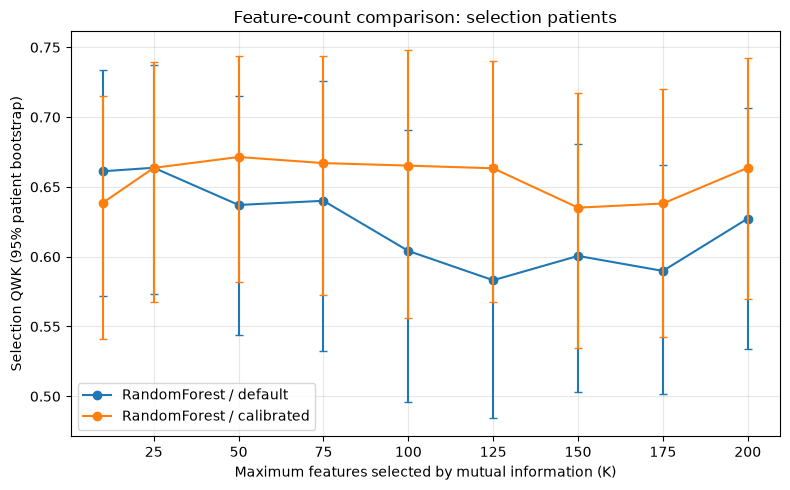

,stage,model,strategy,dataset,nodules,patients,thresholds,accuracy,balanced_accuracy,mse,...,weighted_mae,qwk,f1_macro,f1_weighted,predictors,qwk_lower,qwk_upper,test,info_gain_k,selected_by_selection_qwk
0,selection,RandomForest,default,pooled,425,137,"[1.5, 2.5, 3.5, 4.5]",0.5082,0.4366,0.6259,...,0.6193,0.6612,0.4402,0.5078,758,0.5719,0.7334,teste1,10,True
3,selection,RandomForest,calibrated,pooled,425,137,"[1.4780851850602639, 2.4173701198411885, 3.675...",0.5082,0.4570,0.6847,...,0.6323,0.6387,0.4753,0.5079,758,0.5411,0.7153,teste1,10,False
6,selection,RandomForest,default,pooled,425,137,"[1.5, 2.5, 3.5, 4.5]",0.5271,0.4535,0.6094,...,0.6053,0.6637,0.4588,0.5245,758,0.5733,0.7376,teste2,25,True
9,selection,RandomForest,calibrated,pooled,425,137,"[1.87642516502279, 2.320111820140975, 3.667888...",0.5365,0.5246,0.7247,...,0.5819,0.6636,0.4927,0.5146,758,0.5678,0.7396,teste2,25,False
12,selection,RandomForest,default,pooled,425,137,"[1.5, 2.5, 3.5, 4.5]",0.5082,0.4287,0.6424,...,0.6539,0.6371,0.4438,0.5087,758,0.5436,0.7154,teste3,50,False
15,selection,RandomForest,calibrated,pooled,425,137,"[1.806334885369996, 2.314081337568637, 3.42214...",0.5529,0.5093,0.6706,...,0.5786,0.6714,0.5066,0.5376,758,0.5820,0.7437,teste3,50,True
18,selection,RandomForest,default,pooled,425,137,"[1.5, 2.5, 3.5, 4.5]",0.5294,0.4479,0.6447,...,0.6321,0.6400,0.4610,0.5285,758,0.5327,0.7258,teste4,75,False
21,selection,RandomForest,calibrated,pooled,425,137,"[1.913170016807753, 2.3222521667438696, 3.5667...",0.5576,0.5162,0.6871,...,0.5785,0.6670,0.4972,0.5247,758,0.5727,0.7440,teste4,75,True
24,selection,RandomForest,default,pooled,425,137,"[1.5, 2.5, 3.5, 4.5]",0.5106,0.4288,0.6988,...,0.6902,0.6041,0.4440,0.5089,758,0.4956,0.6910,teste5,100,False
27,selection,RandomForest,calibrated,pooled,425,137,"[1.9174186050036668, 2.166016193954394, 3.1417...",0.5647,0.5391,0.7035,...,0.5554,0.6652,0.5118,0.5228,758,0.5563,0.7482,teste5,100,True


In [6]:
FEATURE_COUNT_VALUES = (10, 25, 50, 75, 100, 125, 150, 175, 200)
sweep_selection_metrics = run_feature_count_sweep(
    training,
    feature_columns,
    shared_split,
    RUN_DIR,
    feature_counts=FEATURE_COUNT_VALUES,
    fit_settings=FIT_SETTINGS,
    evaluation_settings=EVALUATION_SETTINGS,
    n_bootstrap=N_BOOTSTRAP,
)
display(sweep_selection_metrics.loc[sweep_selection_metrics.dataset.eq("pooled")].round(4))


### Leitura da experiência com o número de características

Com limiares calibrados, K = 50 obteve a maior QWK de seleção (**0,6714**). Adota-se, contudo, `INFO_GAIN_K = 200`, que apresentou a maior exatidão (**0,5835**), o maior F1 macro (**0,5335**) e o menor MAE (**0,4965**) entre os valores avaliados com limiares calibrados, mantendo uma QWK próxima (**0,6637**). A escolha privilegia este compromisso entre as métricas de seleção, sem recorrer à validação.

Nesta partição, o filtro de correlação reteve 193 características. Com K = 200 (e com qualquer K >= 193), a seleção por informação mútua não remove nenhuma característica: a configuração escolhida equivale, na prática, a não usar seleção por informação mútua, e o PCA recebe todas as características que passam o filtro de correlação. Este é também um resultado da experiência: reter menos características do que as deixadas pelo filtro de correlação não melhorou as métricas de seleção de forma consistente. Como o filtro é reajustado nos dados de cada modelo, o número de características retidas pode mudar no reajuste final; se ultrapassar 200, a seleção volta a remover algumas.

## Experiências com variáveis-alvo alternativas

Reutiliza-se o manifesto holdout e a coorte radiómica para comparar uma variável-alvo binária (`rating < 3` versus `rating >= 3`) com três variáveis-alvo ordinais definidas por diferentes pontos de corte das classificações. Para cada variável-alvo, o pré-processamento e o modelo são ajustados apenas nos pacientes de ajuste; as estratégias `default` e `calibrated` comparam limiares fixos nos pontos médios das classes com limiares calibrados nos pacientes de limiares, e ambas são avaliadas nos pacientes de seleção. Os pacientes de validação não são previstos. Os valores de QWK são significativos dentro de cada definição da variável-alvo, mas não permitem ordenar diretamente definições diferentes.

Estas experiências usam explicitamente `training_target="label"`, pois o alvo é a classe binária ou ordinal obtida pelo mapeamento, em vez da média original na escala 1 a 5.


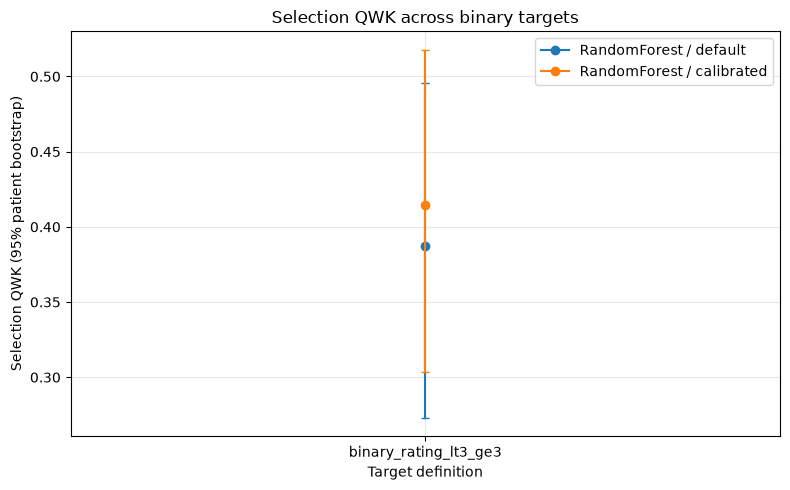

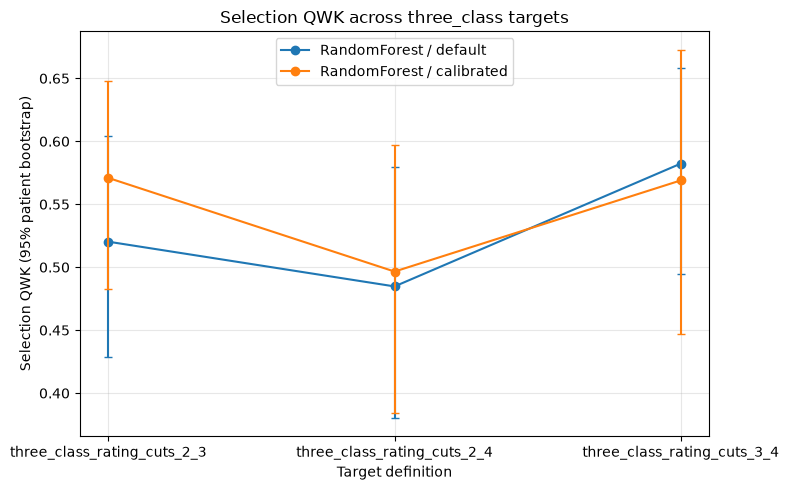

,target_name,target_classes,target_mapping,winner_model,winner_strategy,winner_selection_qwk,winner_selection_qwk_lower,winner_selection_qwk_upper,winner_selection_accuracy,validated_thresholds,selection_patients,selection_nodules
0,binary_rating_lt3_ge3,"0,1","{""1"": 0, ""2"": 0, ""3"": 1, ""4"": 1, ""5"": 1}",RandomForest,calibrated,0.4143,0.3037,0.5178,0.7318,[0.4576497211208742],137,425
1,three_class_rating_cuts_2_3,"1,2,3","{""1"": 1, ""2"": 1, ""3"": 2, ""4"": 3, ""5"": 3}",RandomForest,calibrated,0.5709,0.4831,0.6476,0.6282,"[1.6324902615571437, 2.372097938797824]",137,425
2,three_class_rating_cuts_2_4,"1,2,3","{""1"": 1, ""2"": 1, ""3"": 2, ""4"": 2, ""5"": 3}",RandomForest,calibrated,0.4965,0.3843,0.5968,0.6988,"[1.5071170646967116, 2.3360508713931]",137,425
3,three_class_rating_cuts_3_4,"1,2,3","{""1"": 1, ""2"": 1, ""3"": 1, ""4"": 2, ""5"": 3}",RandomForest,default,0.5823,0.4946,0.6581,0.8071,"[1.5, 2.5]",137,425


In [7]:
TARGET_EXPERIMENTS = [
    {"name": "binary_rating_lt3_ge3", "mapping": {1: 0, 2: 0, 3: 1, 4: 1, 5: 1}},
    *[
        {
            "name": f"three_class_rating_cuts_{first}_{second}",
            "mapping": rating_target_mapping((first, second)),
        }
        for first, second in ((2, 3), (2, 4), (3, 4))
    ],
]
all_target_selection, target_summary = run_target_comparisons(
    training,
    feature_columns,
    shared_split,
    RUN_DIR,
    targets=TARGET_EXPERIMENTS,
    fit_settings={**FIT_SETTINGS, "training_target": "label"},
    evaluation_settings=EVALUATION_SETTINGS,
    n_bootstrap=N_BOOTSTRAP,
)
display(target_summary.round(4))


### Leitura das experiências com variáveis-alvo alternativas

Na experiência de três classes que agrupa as classificações 1 a 3 e mantém 4 e 5 como classes distintas, a estratégia `default` obteve QWK de seleção **0,5823**. Este valor não permite ordenar este agrupamento face aos restantes nem compará-lo diretamente com o alvo original de cinco classes, porque as definições das classes são diferentes. As experiências são avaliadas apenas na partição de seleção e usam `training_target="label"`.

## Painel visual das experiências

Estes gráficos resumem os resultados guardados sem voltar a ajustar os modelos: métricas por número de características, representação das classes da variável-alvo, matrizes de confusão normalizadas com as previsões dos pacientes de seleção e QWK por conjunto de dados nos pacientes de seleção. As distribuições das classes apresentam as contagens de nódulos e de pacientes. As matrizes de confusão e os resultados por conjunto de dados facilitam a identificação de erros específicos das classes e da variabilidade; as definições da variável-alvo são apresentadas separadamente.

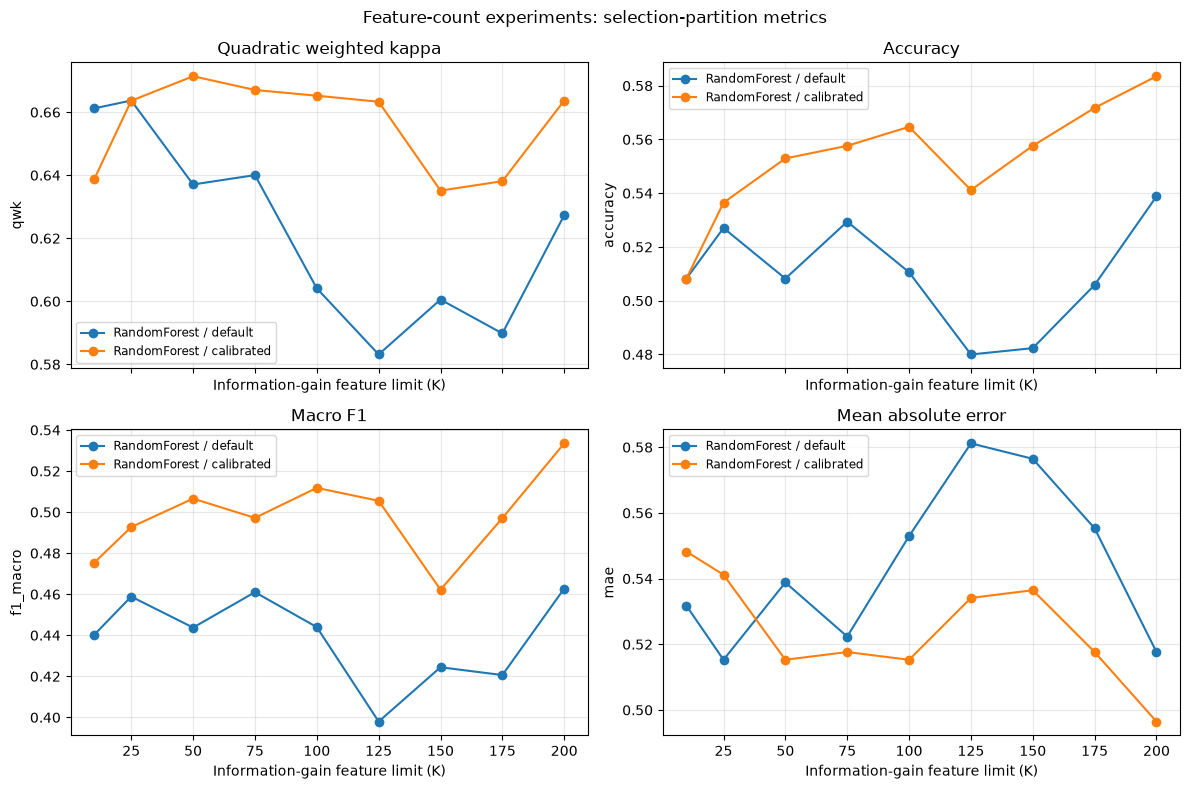

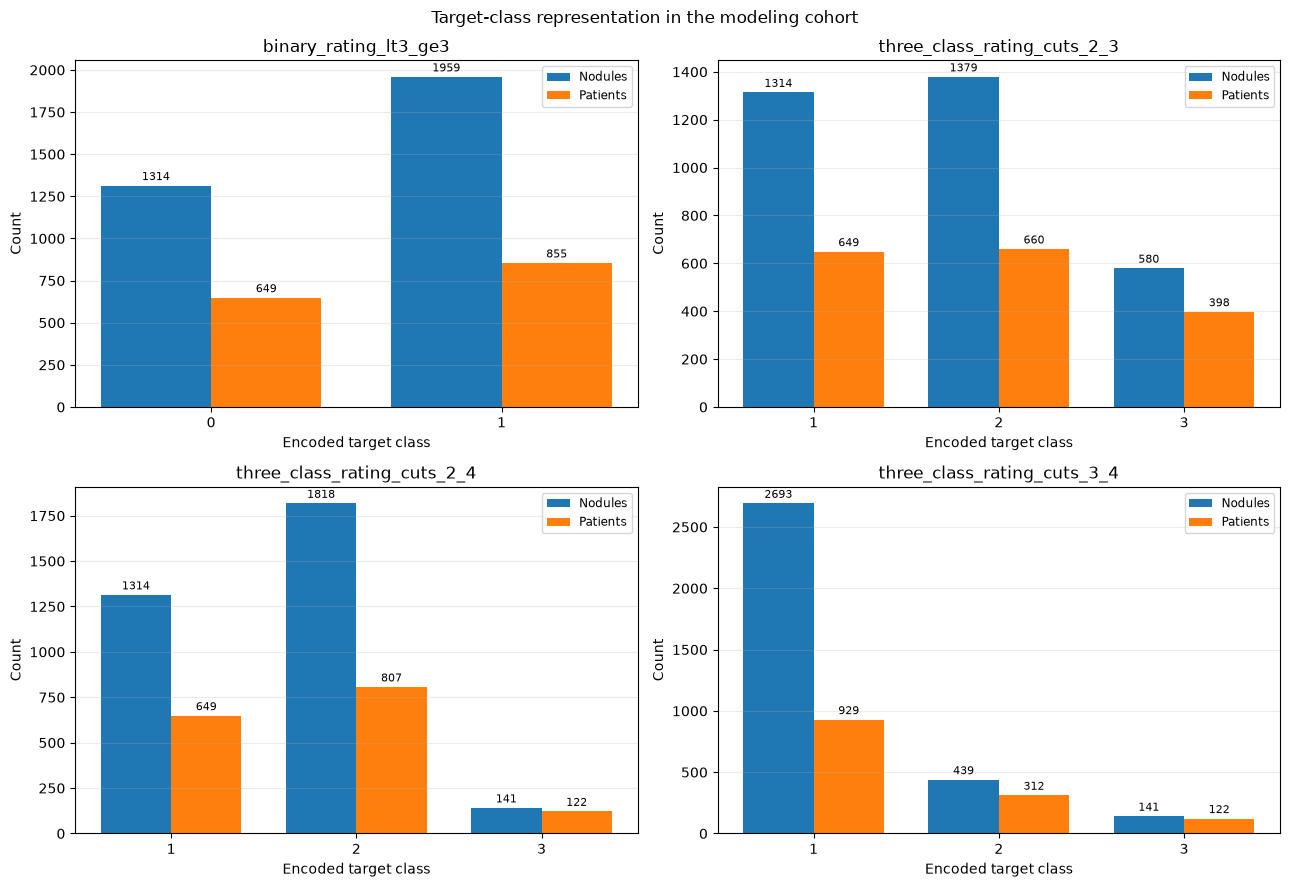

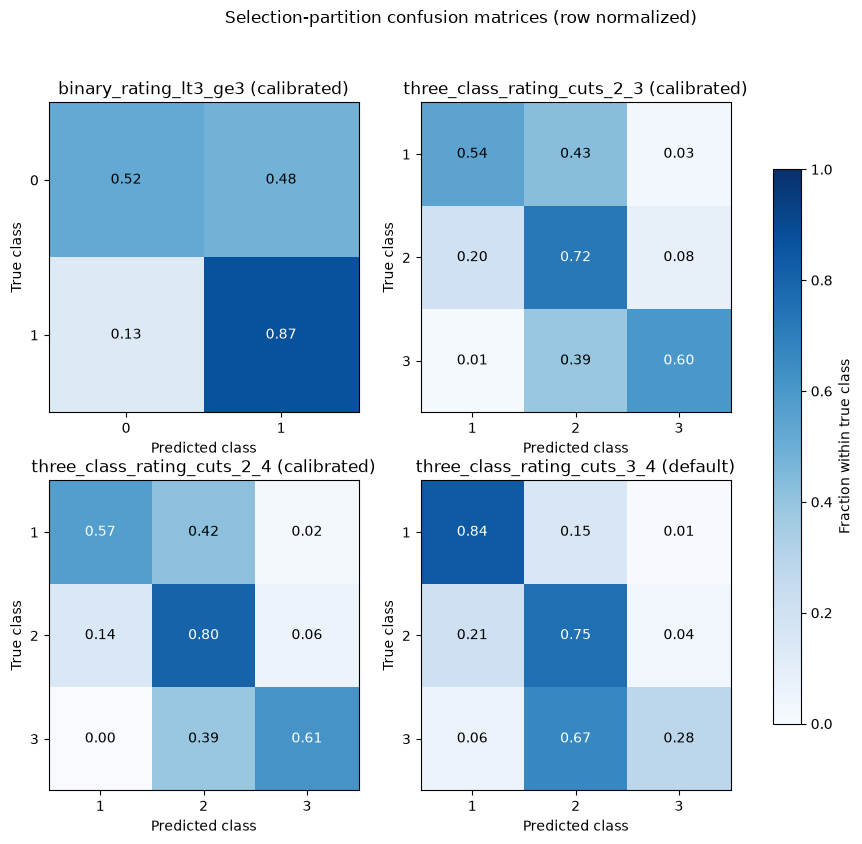

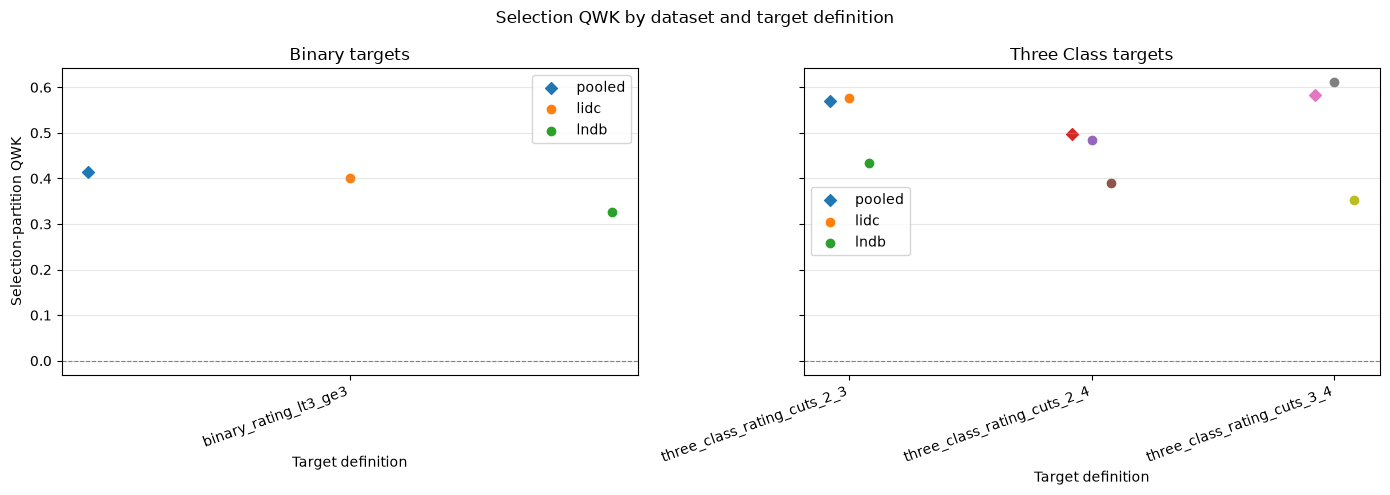

In [8]:
plot_contour_comparisons(
    training,
    sweep_selection_metrics,
    TARGET_EXPERIMENTS,
    all_target_selection,
    target_summary,
    RUN_DIR,
)


## Experiência: hiperparâmetros do Random Forest

Comparam-se alterações a `n_estimators`, `max_depth` e `min_samples_leaf`, um parâmetro de cada vez, mantendo os restantes ajustes e o manifesto de pacientes fixos. A configuração base é incluída como referência. Para cada parâmetro, escolhe-se o valor com maior QWK agregada nos pacientes de seleção, na melhor das duas estratégias de limiares; os valores escolhidos substituem os base em `SELECTED_FIT_SETTINGS`, usada no modelo de 5 classes e como candidata no modelo de triagem. Os pacientes de validação não são previstos nem usados para escolher parâmetros. Como cada parâmetro varia isoladamente, a combinação dos três não é avaliada nesta experiência; a sua QWK de seleção aparece na secção do modelo de 5 classes. Os gráficos mostram a QWK de seleção com intervalos bootstrap por paciente e as métricas secundárias, separadas por estratégia de limiar. Os resultados e a configuração de cada execução ficam em `hyperparameter_sweep/`, dentro da pasta da experiência.

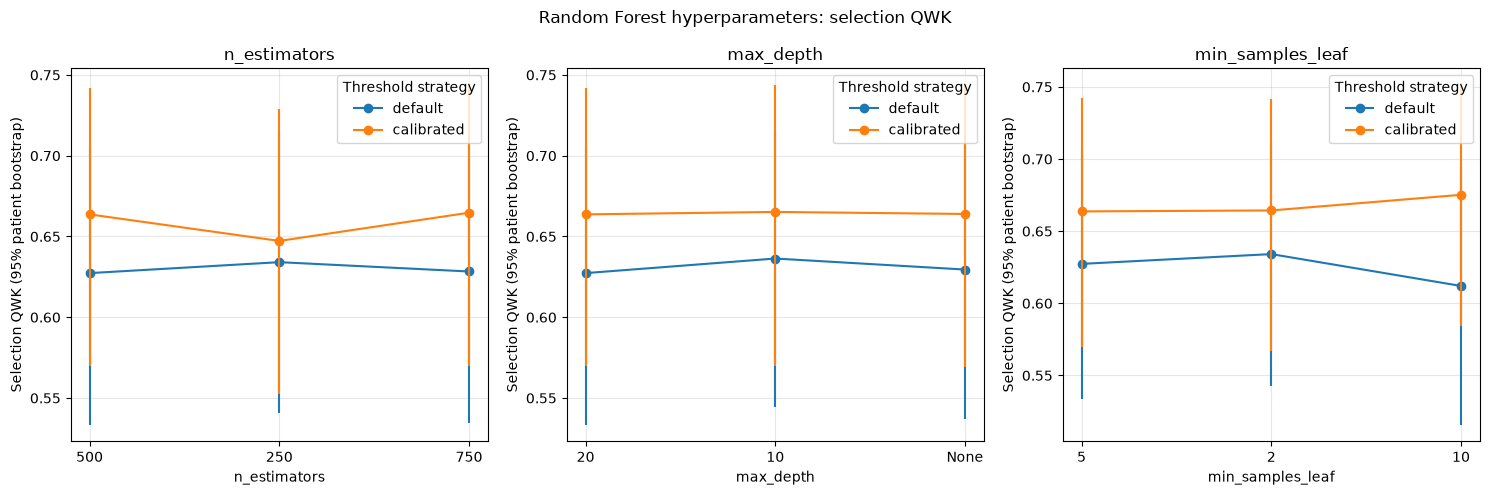

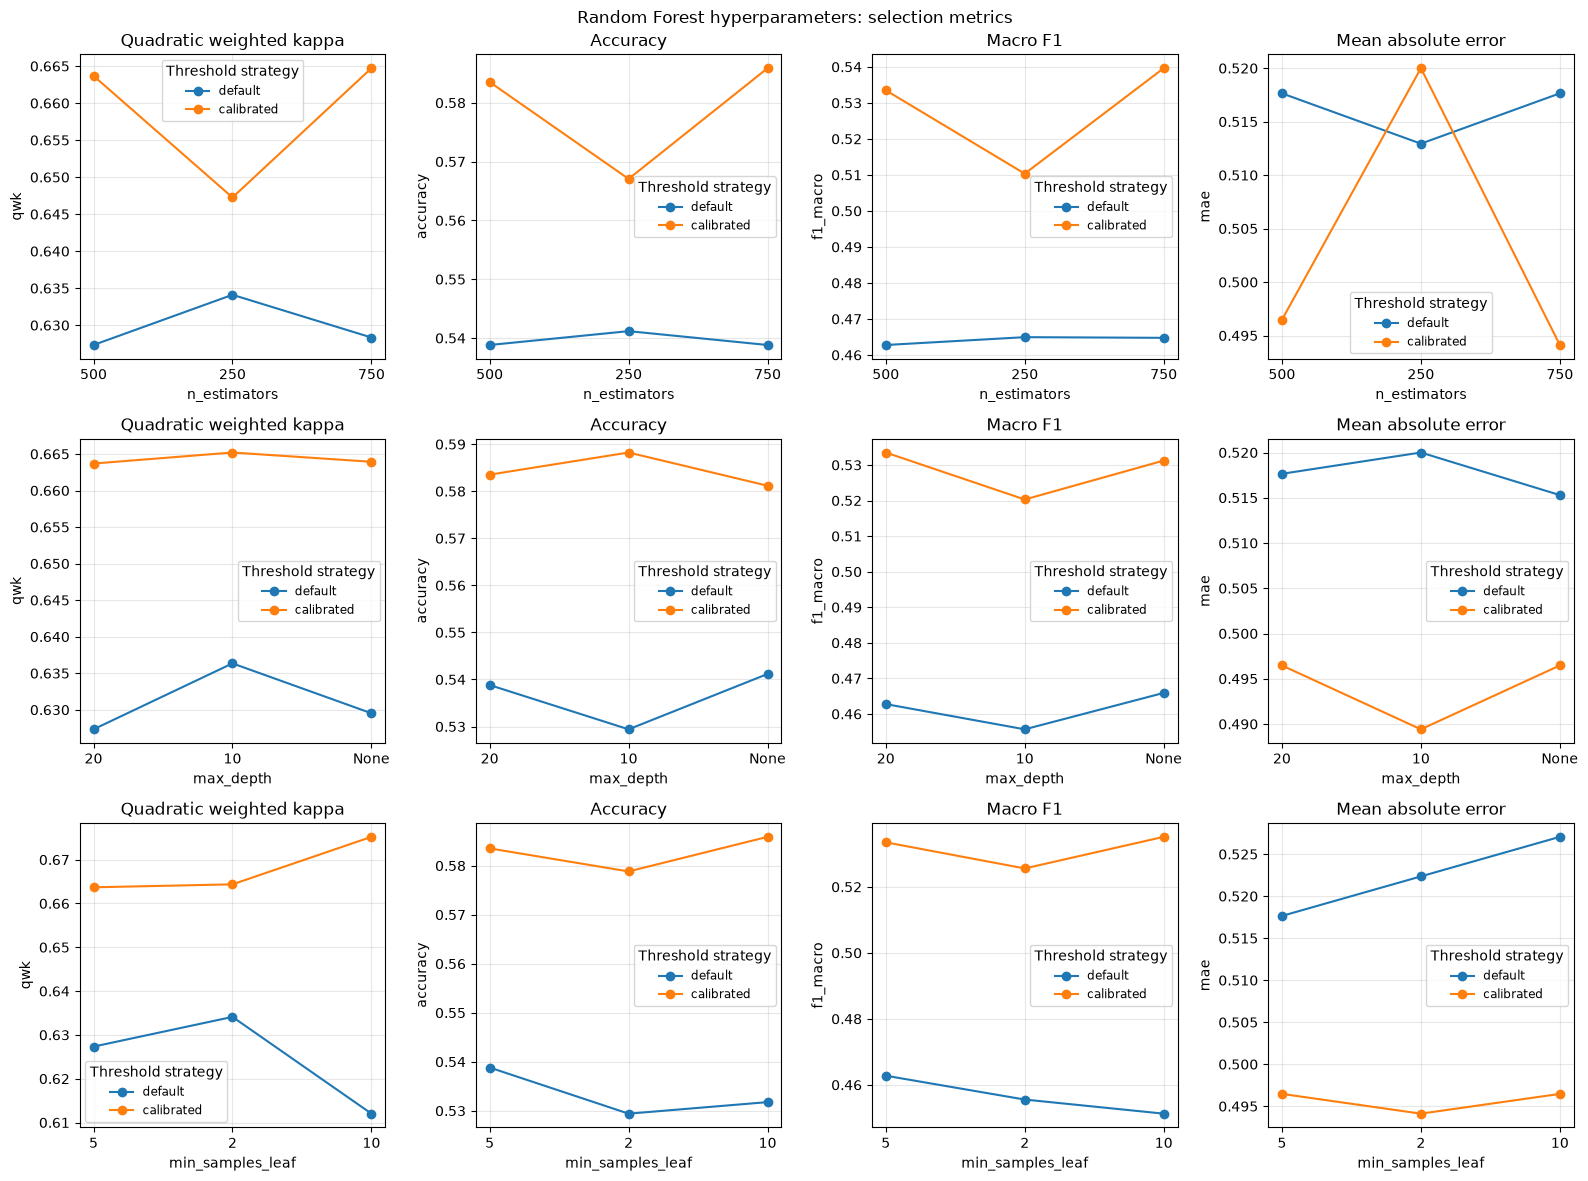

,hyperparameter,value_label,strategy,qwk,qwk_lower,qwk_upper,balanced_accuracy,f1_macro,mae
27,max_depth,10,calibrated,0.6652,0.5699,0.7436,0.5224,0.5203,0.4894
24,max_depth,10,default,0.6363,0.5447,0.7143,0.4353,0.4557,0.5200
21,max_depth,20,calibrated,0.6637,0.5697,0.7421,0.5410,0.5335,0.4965
18,max_depth,20,default,0.6273,0.5336,0.7068,0.4429,0.4628,0.5176
33,max_depth,None,calibrated,0.6639,0.5693,0.7431,0.5375,0.5312,0.4965
30,max_depth,None,default,0.6295,0.5367,0.7085,0.4464,0.4659,0.5153
51,min_samples_leaf,10,calibrated,0.6752,0.5841,0.7511,0.5565,0.5352,0.4965
48,min_samples_leaf,10,default,0.6120,0.5160,0.6942,0.4308,0.4513,0.5271
45,min_samples_leaf,2,calibrated,0.6644,0.5668,0.7414,0.5337,0.5256,0.4941
42,min_samples_leaf,2,default,0.6341,0.5425,0.7119,0.4365,0.4555,0.5224


Selected by selection-partition QWK: {'max_depth': 10, 'min_samples_leaf': 10, 'n_estimators': 750}


In [9]:
hyperparameter_selection_metrics = run_hyperparameter_sweep(
    training,
    feature_columns,
    shared_split,
    RUN_DIR,
    parameter_values=HYPERPARAMETER_VALUES,
    fit_settings=FIT_SETTINGS,
    evaluation_settings=EVALUATION_SETTINGS,
    n_bootstrap=N_BOOTSTRAP,
)
display(
    hyperparameter_selection_metrics.loc[
        hyperparameter_selection_metrics.dataset.eq("pooled"),
        [
            "hyperparameter", "value_label", "strategy", "qwk", "qwk_lower",
            "qwk_upper", "balanced_accuracy", "f1_macro", "mae",
        ],
    ]
    .sort_values(["hyperparameter", "value_label", "strategy"])
    .round(4)
)
SELECTED_HYPERPARAMETERS = best_hyperparameters(hyperparameter_selection_metrics)
SELECTED_FIT_SETTINGS = {**FIT_SETTINGS, **SELECTED_HYPERPARAMETERS}
print("Selected by selection-partition QWK:", SELECTED_HYPERPARAMETERS)

### Leitura da experiência com hiperparâmetros

Com limiares calibrados, a QWK de seleção foi **0,6752** com `min_samples_leaf = 10` (contra **0,6637** com 5 e **0,6644** com 2), **0,6652** com `max_depth = 10` (contra **0,6637** com 20 e **0,6639** sem limite) e **0,6647** com `n_estimators = 750` (contra **0,6637** com 500 e **0,6473** com 250). Escolhem-se, por isso, 750 árvores, profundidade máxima 10 e folhas com pelo menos 10 nódulos. As diferenças são pequenas face aos intervalos bootstrap de 95% (cerca de 0,17 de largura), sobretudo no número de árvores e na profundidade, pelo que estas escolhas devem ser lidas como ajustes finos e não como melhorias demonstradas.


## Modelo de 5 classes: seleção, validação e reajuste final

A configuração usada é `SELECTED_FIT_SETTINGS`: a configuração base, com `INFO_GAIN_K = 200` escolhido na experiência com o número de características, e os hiperparâmetros escolhidos na experiência anterior. Ajusta-se o RandomForest nos pacientes de ajuste e otimizam-se os limiares calibrados com as suas previsões para os pacientes de limiares. Os pacientes de seleção avaliam as estratégias `default` e `calibrated` com os limiares fixos, e a estratégia com maior QWK agregada prevê os pacientes de validação uma única vez. Por fim, ajusta-se de novo o modelo em todos os pacientes exceto os de limiares e otimizam-se novamente os limiares nesses pacientes, com as previsões do modelo final.

In [10]:
holdout_result = evaluate_contour_holdout(
    training,
    feature_columns,
    shared_split,
    final_cohort=training,
    n_bootstrap=N_BOOTSTRAP,
    **SELECTED_FIT_SETTINGS,
    **EVALUATION_SETTINGS,
)
winner = holdout_result["winner"]
selected_model, selected_strategy = winner["model"], winner["strategy"]
validated_thresholds = holdout_result["validated_thresholds"]
selected_thresholds = holdout_result["final_thresholds"]
selected_artifact = holdout_result["final_model"]
selection_metrics = holdout_result["selection_metrics"]
display(selection_metrics.round(4))
print(
    "Selected by selection-partition QWK:",
    selected_model,
    selected_strategy,
    f"QWK={winner.qwk:.4f}",
    validated_thresholds.round(4),
)


Holdout: fitting RandomForest on 547 fitting patients


Holdout: RandomForest / calibrated predicts 210 validation patients once


Final refit on 894 patients outside the threshold partition


,stage,model,strategy,dataset,nodules,patients,thresholds,accuracy,balanced_accuracy,mse,rmse,mae,weighted_mae,qwk,f1_macro,f1_weighted,predictors
0,selection,RandomForest,default,pooled,425,137,"[1.5, 2.5, 3.5, 4.5]",0.5294,0.4291,0.6635,0.8146,0.5318,0.7030,0.6097,0.4497,0.5263,758
1,selection,RandomForest,default,lidc,333,110,"[1.5, 2.5, 3.5, 4.5]",0.5435,0.4463,0.5886,0.7672,0.4985,0.6520,0.6413,0.4675,0.5409,758
2,selection,RandomForest,default,lndb,92,27,"[1.5, 2.5, 3.5, 4.5]",0.4783,0.3322,0.9348,0.9668,0.6522,0.9736,0.4045,0.3302,0.4573,758
3,selection,RandomForest,calibrated,pooled,425,137,"[2.0032192974930236, 2.342579894310548, 3.3302...",0.5788,0.5541,0.6988,0.8360,0.5059,0.5772,0.6690,0.5354,0.5593,758
4,selection,RandomForest,calibrated,lidc,333,110,"[2.0032192974930236, 2.342579894310548, 3.3302...",0.6186,0.6042,0.5856,0.7652,0.4414,0.5025,0.7090,0.5788,0.5970,758
5,selection,RandomForest,calibrated,lndb,92,27,"[2.0032192974930236, 2.342579894310548, 3.3302...",0.4348,0.3163,1.1087,1.0529,0.7391,0.9141,0.4346,0.3072,0.4205,758


Selected by selection-partition QWK: RandomForest calibrated QWK=0.6690 [2.0032 2.3426 3.3303 3.9022]


### Leitura dos resultados da seleção

Na partição de seleção, a estratégia calibrada obteve QWK **0,6690**, face a **0,6097** com a estratégia `default`, sendo por isso a escolhida. A combinação dos hiperparâmetros escolhidos supera ligeiramente a configuração base (**0,6637** com limiares calibrados), mas fica abaixo da melhor alteração isolada (`min_samples_leaf = 10`, **0,6752**). Não se demonstrou uma melhoria consistente pela combinação. A melhoria dos limiares calibrados concentrou-se no LIDC (**0,7090** contra **0,6413**); no LNDb, a diferença foi menor (**0,4346** contra **0,4045**). Estes resultados orientam a escolha da estratégia; o desempenho final é avaliado separadamente na partição de validação.

## Avaliação na validação, incerteza e estabilidade dos limiares

Os resultados de validação medem a configuração escolhida em pacientes que ficaram fora do ajuste, da calibração dos limiares e da seleção desta configuração. Este isolamento descreve o protocolo desta execução; a reutilização da mesma partição ao longo do desenvolvimento limita a independência da estimativa, como se explicita na reformulação para triagem. Um único holdout não tem variabilidade entre partições; por isso, os intervalos de 95% resultam de reamostrar pacientes completos de validação dentro de cada conjunto de dados (2 000 reamostragens). Estes intervalos descrevem a variabilidade de amostragem deste conjunto de validação, não a variabilidade do treino. A comparação dos limiares mostra os pontos de corte validados e finais, e as classificações que cada um produz nos pacientes de limiares; uma diferença grande indica que o reajuste final deve ser inspecionado. Escolher as definições radiómicas com base nos resultados de validação faria com que estes passassem a servir de evidência para a seleção.

,stage,model,strategy,dataset,nodules,patients,thresholds,accuracy,balanced_accuracy,mse,rmse,mae,weighted_mae,qwk,f1_macro,f1_weighted
0,validation,RandomForest,calibrated,pooled,655,210,"[2.0032192974930236, 2.342579894310548, 3.3302...",0.5710,0.5216,0.6214,0.7883,0.4870,0.5705,0.6921,0.5215,0.5480
1,validation,RandomForest,calibrated,lidc,512,169,"[2.0032192974930236, 2.342579894310548, 3.3302...",0.5938,0.5494,0.5645,0.7513,0.4551,0.5180,0.6993,0.5480,0.5708
2,validation,RandomForest,calibrated,lndb,143,41,"[2.0032192974930236, 2.342579894310548, 3.3302...",0.4895,0.3539,0.8252,0.9084,0.6014,0.9451,0.5865,0.3337,0.4592


estimate                   lower                   upper  \
dataset               lidc    lndb  pooled    lidc    lndb  pooled    lidc   
metric                                                                       
balanced_accuracy   0.5494  0.3539  0.5216  0.4868  0.2909  0.4673  0.6089   
f1_macro            0.5480  0.3337  0.5215  0.4847  0.2649  0.4635  0.6026   
mae                 0.4551  0.6014  0.4870  0.4011  0.4711  0.4367  0.5143   
qwk                 0.6993  0.5865  0.6921  0.6354  0.4131  0.6302  0.7527   

                                   
dataset              lndb  pooled  
metric                             
balanced_accuracy  0.4200  0.5734  
f1_macro           0.3976  0.5718  
mae                0.7460  0.5449  
qwk                0.7168  0.7453

,cut_point,validated,final,difference
0,1|2,2.0032,2.0071,0.0038
1,2|3,2.3426,2.5000,0.1574
2,3|4,3.3303,3.5770,0.2467
3,4|5,3.9022,3.9774,0.0752


,rating,observed,validated_predicted,final_predicted
0,1,72,84,84
1,2,124,71,126
2,3,207,253,205
3,4,66,54,42
4,5,21,28,33


,candidate_id,patient_id,dataset,malignancy_target,stage,model,strategy,continuous_prediction,prediction,absolute_error
2706,LNDb-0053_finding2,LNDb-0053,lndb,5.0,validation,RandomForest,calibrated,1.991364,1,4
969,1.3.6.1.4.1.14519.5.2.1.6279.6001.213022585153...,LIDC-IDRI-0432,lidc,1.0,validation,RandomForest,calibrated,3.377410,4,3
686,1.3.6.1.4.1.14519.5.2.1.6279.6001.185154482385...,LIDC-IDRI-0119,lidc,1.0,validation,RandomForest,calibrated,3.371080,4,3
1782,1.3.6.1.4.1.14519.5.2.1.6279.6001.302876782304...,LIDC-IDRI-0993,lidc,1.0,validation,RandomForest,calibrated,3.511508,4,3
2705,LNDb-0053_finding1,LNDb-0053,lndb,2.0,validation,RandomForest,calibrated,3.844230,4,2
2417,1.3.6.1.4.1.14519.5.2.1.6279.6001.855232435861...,LIDC-IDRI-1009,lidc,2.0,validation,RandomForest,calibrated,3.842035,4,2
3032,LNDb-0208_finding2,LNDb-0208,lndb,5.0,validation,RandomForest,calibrated,3.225047,3,2
2761,LNDb-0069_finding1,LNDb-0069,lndb,1.0,validation,RandomForest,calibrated,2.698704,3,2
2762,LNDb-0069_finding2,LNDb-0069,lndb,4.0,validation,RandomForest,calibrated,2.140132,2,2
3005,LNDb-0185_finding3,LNDb-0185,lndb,5.0,validation,RandomForest,calibrated,2.923663,3,2


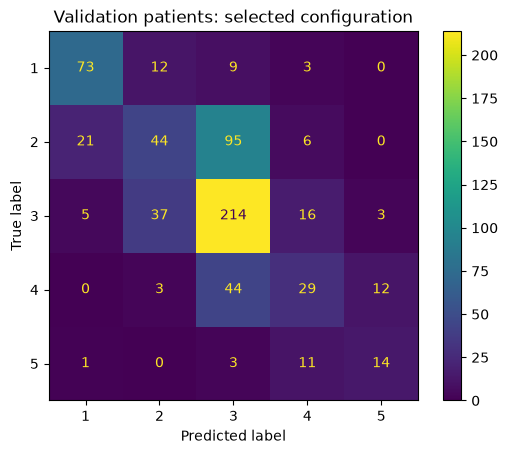

In [11]:
metric_columns = list(calculate_metrics([1, 2, 3, 4, 5], [1, 2, 3, 4, 5]))
validation_metrics = holdout_result["validation_metrics"]
validation_intervals = holdout_result["validation_intervals"]
display(validation_metrics.round(4))
display(
    validation_intervals.pivot(
        index="metric", columns="dataset", values=["estimate", "lower", "upper"]
    ).round(4)
)
display(holdout_result["threshold_check"].round(4))
display(holdout_result["threshold_rating_counts"])
validation_errors = holdout_result["validation_predictions"].copy()
y_validation = validation_errors.malignancy_target.astype(int)
validation_predictions = validation_errors.prediction.to_numpy()
validation_errors["absolute_error"] = abs(y_validation.to_numpy() - validation_predictions)
display(validation_errors.sort_values("absolute_error", ascending=False).head(10))
ConfusionMatrixDisplay.from_predictions(y_validation, validation_predictions, labels=[1, 2, 3, 4, 5])
plt.title("Validation patients: selected configuration")
plt.show()


### Leitura dos resultados de validação

Na validação, a QWK foi **0,6921** no conjunto agregado, **0,6993** no LIDC e **0,5865** no LNDb. Os intervalos bootstrap de 95% são, respetivamente, **[0,6302; 0,7453]**, **[0,6354; 0,7527]** e **[0,4131; 0,7168]**. A estimativa do LNDb é inferior à do LIDC e o seu intervalo é largo, com apenas 41 pacientes. A sobreposição dos intervalos individuais não constitui um teste da diferença de QWK entre os dois conjuntos; essa diferença é aqui descritiva.

A exatidão equilibrada e o F1 macro também são inferiores no LNDb (**0,3539** e **0,3337**) aos do LIDC (**0,5494** e **0,5480**). O MAE agregado foi **0,4870**.

#### Estabilidade dos limiares entre o modelo validado e o modelo final

O modelo validado (ajustado nos 547 pacientes de ajuste) e o modelo final (ajustado nos 894 pacientes fora da partição de limiares) são modelos diferentes, e os limiares de cada um são otimizados nos mesmos 158 pacientes de limiares, com as suas próprias previsões. Os cortes 1|2 e 4|5 quase não mudam (+0,004 e +0,075), mas o corte 2|3 sobe 0,16 (de 2,34 para 2,50) e o corte 3|4 sobe 0,25 (de 3,33 para 3,58).

Nos 490 nódulos dos pacientes de limiares (observados: 72, 124, 207, 66 e 21 nas classes 1 a 5), o modelo validado prevê 84, **71**, 253, 54 e 28, e o modelo final 84, 126, 205, **42** e 33:

- **No modelo validado, a classe 2 fica comprimida** numa faixa de apenas 0,34 pontos (de 2,00 a 2,34) e recebe 71 nódulos em vez de 124. A QWK penaliza pouco as confusões entre classes vizinhas, como 2 e 3, pelo que a otimização global pode favorecer esses erros sem preservar as contagens de cada classe.
- **O modelo final aproxima-se das contagens observadas nas classes 2 e 3**, mas prevê menos nódulos de classe 4 e mais de classe 5.
- **O corte 3|4 é o que mais muda.** Uma previsão entre 3,33 e 3,58 corresponde à classe 4 com os limiares validados e à classe 3 com os finais.
- **A estimativa de validação refere-se ao modelo validado com os seus próprios limiares.** Os limiares finais são ajustados e verificados nos mesmos pacientes de limiares, sem confirmação independente; é uma limitação do reajuste final.

## Guardar a avaliação holdout e o modelo final

Guardam-se em conjunto as métricas e previsões de seleção, limiares e validação, os intervalos bootstrap, a comparação dos limiares, o modelo validado e o modelo final com os respetivos limiares, os planos exatos por paciente, as identidades efetivamente usadas no treino, as configurações e a proveniência. O modelo final não recebe uma nova pontuação independente. A inferência para a competição é feita no notebook 05.

In [12]:
save_holdout_run(
    PROJECT_ROOT,
    RUN_DIR,
    holdout_result,
    pipeline="contour",
    fit_settings=SELECTED_FIT_SETTINGS,
    evaluation_settings=EVALUATION_SETTINGS,
    manifest=shared_split,
    split_path=SPLIT_PATH,
    input_hashes=input_sha256,
    metadata={
        "roi_definition": "reader_union",
        "include_characteristics": INCLUDE_CHARACTERISTICS,
        "requested_features": feature_columns,
        "base_fit_settings": FIT_SETTINGS,
        "selected_hyperparameters": SELECTED_HYPERPARAMETERS,
        "radiomics_settings_id": configuration["settings_id"],
        "contour_feature_cache": feature_cache_metadata,
    },
)


## Equidade e desempenho por subgrupo

Verifica-se se o modelo validado de 5 classes erra de forma diferente entre grupos de nódulos dos pacientes de validação, sem novo ajuste; as experiências com variáveis-alvo alternativas não são auditadas, e o modelo de triagem tem uma auditoria própria, mais curta, na secção de triagem. Sexo e idade faltam na maioria dos pacientes do LIDC e não existem no LNDb, que também não regista o fabricante do equipamento, pelo que nenhum destes atributos é analisado. Comparam-se o conjunto de dados, o tamanho do nódulo (diâmetro da esfera equivalente ao contorno de união dos leitores), a espessura de corte, o número de leitores e a amplitude das suas classificações.

`high_recall` é a fração dos nódulos com classificação 4 ou 5 que o modelo também coloca em 4 ou 5; `false_high_rate` é a mesma fração entre os nódulos classificados de 1 a 3. As diferenças entre grupos têm intervalos de 95% obtidos por reamostragem de pacientes dentro de cada conjunto de dados. As tabelas e a figura ficam em `fairness/`, no diretório da experiência.


nodules  patients    mae  mean_signed_error    qwk  \
attribute  group                                                             
dataset    lidc             512       169  0.455              0.104  0.699   
           lndb             143        41  0.601             -0.084  0.587   
size_band  10-20 mm          93        71  0.602              0.194  0.562   
           6-10 mm          283       140  0.428              0.060  0.597   
           <6 mm            250       110  0.492             -0.020  0.546   
           >=20 mm           29        25  0.655              0.379  0.206   
slice_band 1.5-2.5 mm        38        17  0.579              0.316  0.473   
           <=1.5 mm         448       139  0.493              0.016  0.666   
           >2.5 mm          169        54  0.450              0.130  0.756   
readers    1 reader         261       114  0.567             -0.008  0.597   
           2 readers        147        91  0.517              0.014  0.587   
           >=3 readers      247       130  0.385              0.166  0.792   
agreement  range 0          365       152  0.526              0.066  0.648   
           range 1          176        96  0.364             -0.057  0.610   
           range >=2        114        80  0.553              0.237  0.674   

                        high_rated  high_recall  false_high_rate  
attribute  group                                                  
dataset    lidc                 99        0.646            0.058  
           lndb                 18        0.111            0.032  
size_band  10-20 mm             49        0.837            0.409  
           6-10 mm              33        0.000            0.024  
           <6 mm                10        0.000            0.000  
           >=20 mm              25        1.000              NaN  
slice_band 1.5-2.5 mm            4          NaN            0.059  
           <=1.5 mm             68        0.412            0.045  
           >2.5 mm              45        0.778            0.073  
readers    1 reader             37        0.297            0.036  
           2 readers            20        0.300            0.047  
           >=3 readers          60        0.817            0.075  
agreement  range 0              44        0.341            0.034  
           range 1              33        0.515            0.049  
           range >=2            40        0.850            0.135

estimate  lower  upper
attribute  group    reference   metric                                     
dataset    lndb     lidc        mae_gap                 0.146  0.009  0.302
                                high_recall_gap        -0.535 -0.727 -0.313
                                false_high_rate_gap    -0.026 -0.064  0.013
size_band  6-10 mm  10-20 mm    mae_gap                -0.175 -0.337 -0.020
                                high_recall_gap        -0.837 -0.938 -0.733
                                false_high_rate_gap    -0.385 -0.525 -0.243
slice_band >2.5 mm  <=1.5 mm    mae_gap                -0.044 -0.178  0.086
                                high_recall_gap         0.366  0.161  0.594
                                false_high_rate_gap     0.028 -0.020  0.089
readers    1 reader >=3 readers mae_gap                 0.182  0.079  0.292
                                high_recall_gap        -0.519 -0.682 -0.349
                                false_high_rate_gap    -0.039 -0.087  0.006

Median diameter of high-rated validation nodules (mm): {'lidc': 13.9, 'lndb': 8.2}


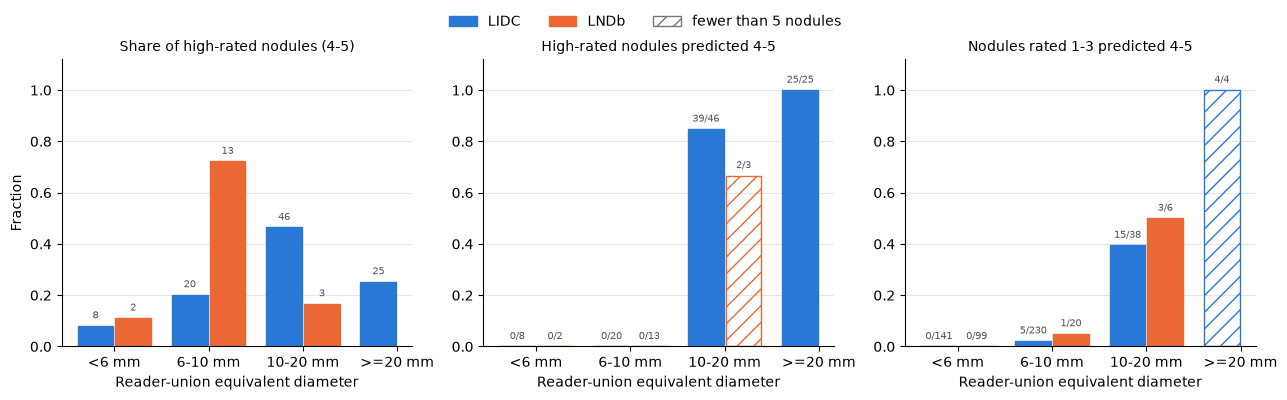

In [13]:
fairness = fairness_audit(
    validation_errors,
    training,
    RUN_DIR / "fairness",
    n_resamples=N_BOOTSTRAP,
    seed=SEED,
)
display(
    fairness["subgroups"].set_index(["attribute", "group"])[
        ["nodules", "patients", "mae", "mean_signed_error", "qwk", "high_rated", "high_recall", "false_high_rate"]
    ].round(3)
)
display(
    fairness["gaps"].set_index(["attribute", "group", "reference", "metric"])[
        ["estimate", "lower", "upper"]
    ].round(3)
)
print(
    "Median diameter of high-rated validation nodules (mm):",
    {name: round(value, 1) for name, value in fairness["high_rated_median_diameter_mm"].items()},
)
plt.show()


### Interpretação

- **O LNDb é pior servido nos nódulos de alto risco.** O modelo coloca em 4 ou 5 apenas 2 dos 18 nódulos do LNDb com essa classificação, contra 64 de 99 no LIDC (diferença -0,54; intervalo de 95% entre -0,73 e -0,31). O erro absoluto médio também é maior no LNDb (diferença 0,15; intervalo entre 0,01 e 0,30), embora o limite inferior esteja próximo de zero.
- **A diferença acompanha o tamanho dos nódulos.** Nenhum nódulo de alto risco com menos de 10 mm é colocado em 4 ou 5 (0 de 43), enquanto entre 10 e 20 mm se identificam 84%, com 41% de falsos altos. Os nódulos de alto risco do LNDb são menores (mediana de 8,2 mm contra 13,9 mm; 13 dos 18 entre 6 e 10 mm) e, na faixa de 6 a 10 mm, nenhum dos dois conjuntos de dados tem nódulos de alto risco colocados em 4 ou 5. Nesta validação, os nódulos pequenos considerados suspeitos pelos leitores são sistematicamente subestimados. A análise não isola o tamanho de outras diferenças entre conjuntos de dados e não demonstra uma causa para a diferença de desempenho.
- **Espessura de corte e número de leitores estão confundidos com a origem e o tamanho.** Todos os exames do LNDb têm cortes até 1,5 mm, e os nódulos com mais leitores tendem a ser maiores, pelo que estas diferenças não são efeitos isolados.
- **Limitações.** Uma única partição de validação com grupos pequenos; as comparações foram escolhidas após uma análise exploratória e não há correção para comparações múltiplas. Os rótulos são opiniões de radiologistas, por isso qualquer enviesamento dos leitores é aprendido pelo modelo. O conjunto de teste do LNDb não tem rótulos públicos e não pode ser auditado.


## Interpretabilidade do modelo

Explica-se o modelo validado de 5 classes, ajustado apenas nos pacientes de ajuste, nos pacientes de validação que previu uma única vez. Nada é reajustado e verifica-se primeiro que o modelo reproduz exatamente as previsões de validação. A floresta recebe as componentes PCA das características retidas após o filtro de correlação e a seleção por informação mútua. As explicações tratam a normalização, a PCA e a floresta como uma única função dessas características, mantendo a interpretação em termos de características com nome.

O cálculo demora alguns minutos, sobretudo por causa do SHAP. As tabelas e as figuras ficam em `interpretability/`, no diretório da experiência.

In [14]:
interpretation = interpretability_audit(
    holdout_result,
    training,
    RUN_DIR / "interpretability",
    n_repeats=10,
    seed=SEED,
)
print(
    f"Validation: {interpretation['validation_nodules']} nodules, "
    f"{interpretation['validation_patients']} patients, QWK {interpretation['baseline_validation_qwk']:.3f}; "
    f"{interpretation['selected_features']} selected features -> {interpretation['pca_components']} PCA components; "
    f"{len(interpretation['size_linked_features'])} size-linked features"
)

/home/rera/aulas/31c/labiacd/lung/project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/rera/aulas/31c/labiacd/lung/project/src/lung_project/interpretability.py:352: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(values.to_numpy(), raw.to_numpy(), feature_names=[short_label(f) for f in values.columns],


Validation: 655 nodules, 210 patients, QWK 0.692; 193 selected features -> 48 PCA components; 30 size-linked features


### Comparação com as características atribuídas pelos radiologistas

Os leitores descreveram cada nódulo com características semânticas. Estas características **não** entram no modelo (`INCLUDE_CHARACTERISTICS=False`); servem para verificar se as previsões variam com os mesmos conceitos clínicos que as classificações dos leitores.

- **Características ordinais** (subtileza, esfericidade, margem, lobulação, espiculação e textura, todas em escalas de 1 a 5): correlação de Spearman com a previsão do modelo, com a classificação média dos leitores e com o diâmetro do nódulo. A linha do diâmetro indica onde a concordância pode refletir apenas o tamanho.
- **Calcificação**, que é categórica (pipoca, laminada, sólida, não central, central, ausente): o código de cada leitor é convertido em variáveis binárias (*one-hot*) e cada nódulo é atribuído à categoria escolhida por mais de metade dos seus leitores (ou a "sem maioria"). Para cada categoria, compara-se a média da previsão e a média da classificação dos leitores com as respetivas médias globais de validação. Categorias com menos de 10 nódulos aparecem tracejadas e não são interpretadas.
- **Estrutura interna**, também categórica, é apenas resumida, porque quase todos os nódulos têm a mesma categoria.

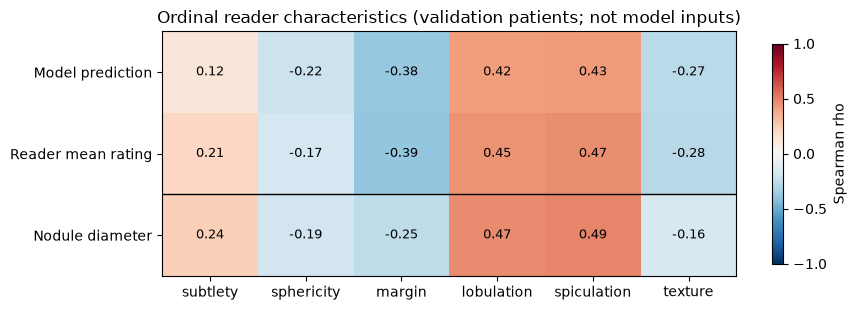

,category,nodules,model_mean,reader_mean,model_shift,reader_shift,too_rare
0,laminated,1,1.53,1.00,-1.07,-1.60,True
1,solid,71,1.60,1.08,-0.99,-1.52,False
2,non-central,5,2.61,2.73,0.02,0.14,True
3,central,15,1.96,1.58,-0.63,-1.02,False
4,absent,546,2.76,2.85,0.17,0.25,False
5,no majority,17,2.01,1.77,-0.59,-0.82,False


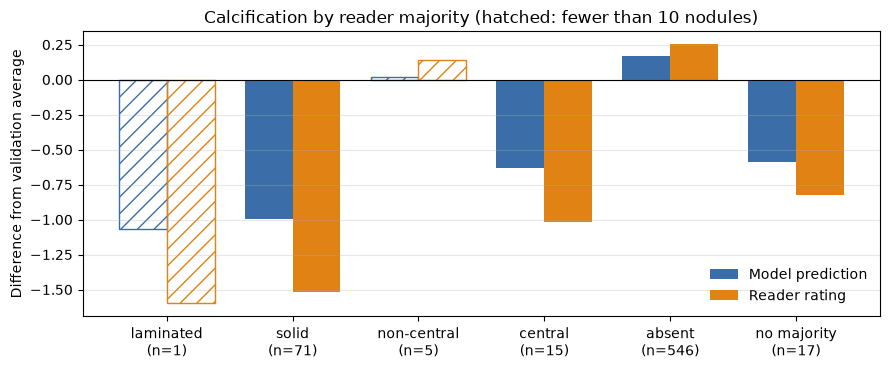

Internal structure: 651/655 validation nodules are soft tissue by reader majority (others: {'no majority': 2, 'fluid': 2}). With so few nodules in the other categories, comparing them with the model is not meaningful.


In [15]:
display(interpretation["figures"]["ordinal"])
display(interpretation["calcification"].round(2))
display(interpretation["figures"]["calcification"])
print(interpretation["internal_structure_note"])

- **As previsões acompanham as características da mesma forma que as classificações dos leitores.** Margem (-0,38 no modelo contra -0,39 nos leitores), lobulação (0,42 contra 0,45), espiculação (0,43 contra 0,47), textura (-0,27 contra -0,28) e esfericidade (-0,22 contra -0,17) têm o mesmo sinal e magnitude semelhante. A subtileza é a exceção mais fraca (0,12 contra 0,21).
- **A lobulação e a espiculação podem refletir sobretudo o tamanho.** O diâmetro sozinho tem correlações iguais ou superiores (0,47 e 0,49), porque nódulos maiores são mais frequentemente lobulados e espiculados. Já a margem e a textura relacionam-se mais com o modelo do que com o diâmetro (-0,38 contra -0,25 e -0,27 contra -0,16), o que sugere informação adicional, mas não demonstra um efeito independente do tamanho.
- **A calcificação é tratada como pelos leitores.** Os nódulos com calcificação sólida (71) recebem previsões 0,99 pontos abaixo da média, e os leitores 1,52; na calcificação central (15), -0,63 contra -1,02. Os nódulos sem calcificação (546) ficam ligeiramente acima da média em ambos (+0,17 e +0,25). O modelo segue a mesma direção com cerca de dois terços da amplitude, coerente com a compressão das previsões para o centro da escala. As categorias laminada (1 nódulo) e não central (5) são demasiado raras para conclusões.

### Que informação usa o modelo?

Baralhar uma característica isolada pode subestimar a sua relevância quando outras características correlacionadas fornecem informação semelhante. Por isso, baralham-se em conjunto todas as características de um grupo, dentro de cada conjunto de dados, e mede-se a perda de QWK na validação (10 repetições). Os grupos são:

- características **ligadas ao tamanho** (|rho de Spearman| >= 0,7 com o volume do contorno nos pacientes de ajuste) e as restantes;
- filtro de imagem e família de características;
- grupos de características correlacionadas (|rho| >= 0,7 nos pacientes de ajuste), identificados pela característica com maior contribuição SHAP média.

O painel PCA mostra quanto a floresta usa cada componente e quais as características com maior peso nas duas componentes mais usadas.

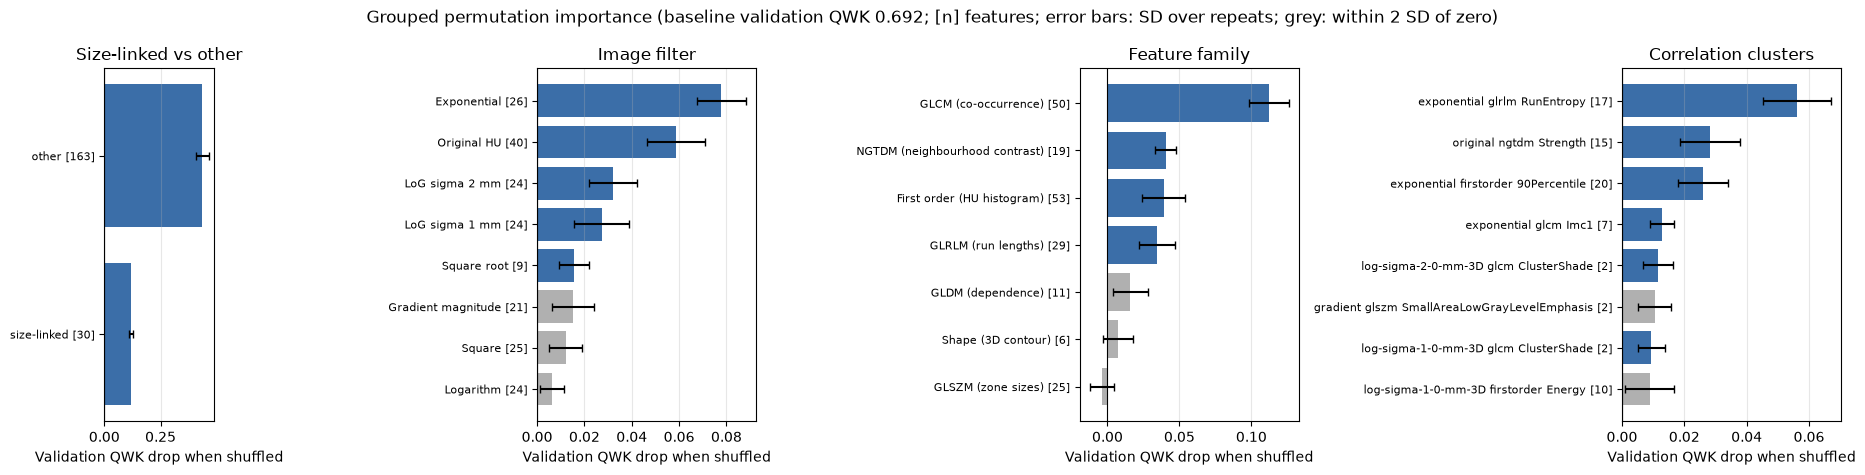

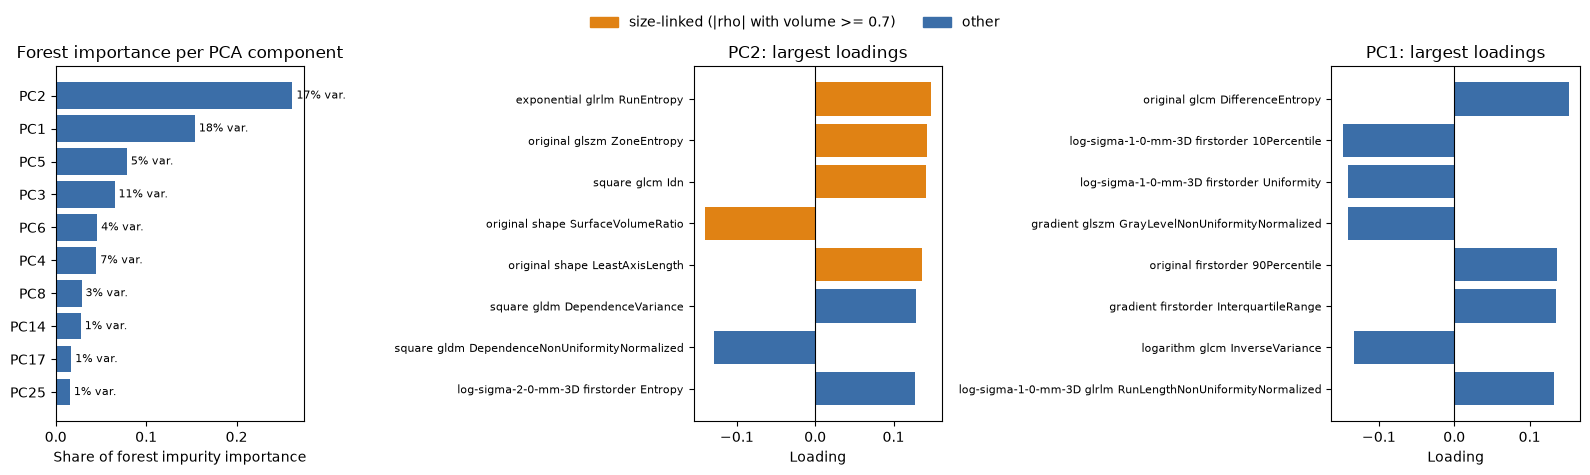

In [16]:
display(interpretation["figures"]["importance"])
display(interpretation["figures"]["pca"])

- **O modelo usa dois eixos principais: tamanho e textura.** A componente mais usada pela floresta é a PC2 (17% da variância e 26% da importância), cujas características com maior peso estão sobretudo ligadas ao tamanho (entropia de *run lengths* após o filtro exponencial, entropia de zonas, relação superfície/volume e menor eixo). Segue-se a PC1 (18% da variância e 15% da importância), dominada por características de intensidade e textura não ligadas ao tamanho (entropia das diferenças GLCM, percentis de intensidade após LoG e na imagem original, dispersão do gradiente).
- **O tamanho entra sobretudo através de características de textura.** 30 das 193 características estão ligadas ao volume, mas apenas 3 destas são de forma; baralhar as 6 características de forma selecionadas custa só 0,007 de QWK.
- **O modelo não depende só do tamanho.** Baralhar as 163 características não ligadas ao tamanho custa 0,44 de QWK, contra 0,12 para as 30 ligadas ao tamanho. Como os grupos têm dimensões muito diferentes, a comparação mostra sobretudo que a informação não ligada ao tamanho é relevante. Os grupos correlacionados mais importantes são representados pela entropia de *run lengths* após o filtro exponencial (17 características, 0,056), pela força NGTDM na imagem original (15 características, 0,028) e pelo percentil 90 após o filtro exponencial (20 características, 0,026), que mede densidade.
- **Filtros e famílias.** Os filtros exponencial (0,08) e original (0,06) são os mais importantes, seguidos dos LoG de 2 mm e 1 mm (0,03 cada). Nas famílias, destaca-se a GLCM (0,11), seguida de NGTDM (0,04), primeira ordem (0,04) e GLRLM (0,03).

### Como o modelo usa as características (SHAP)

O SHAP decompõe a previsão de cada nódulo numa soma de contribuições, uma por característica, a partir da previsão média no conjunto de referência. Uma contribuição positiva aumenta a classificação prevista e uma negativa diminui-a. Usa-se uma aproximação por permutação: avalia-se a contribuição de cada característica em diferentes contextos de características presentes ou substituídas, usando 100 nódulos de referência do conjunto de ajuste. No gráfico, cada ponto é um nódulo de validação, a posição horizontal é a contribuição e a cor é o valor da característica.

Como muitas características estão fortemente correlacionadas, o crédito é repartido entre elas. A ordem exata deve ser lida como "este tipo de característica é importante", e não como uma classificação rigorosa.

Average prediction (SHAP base value): 2.60


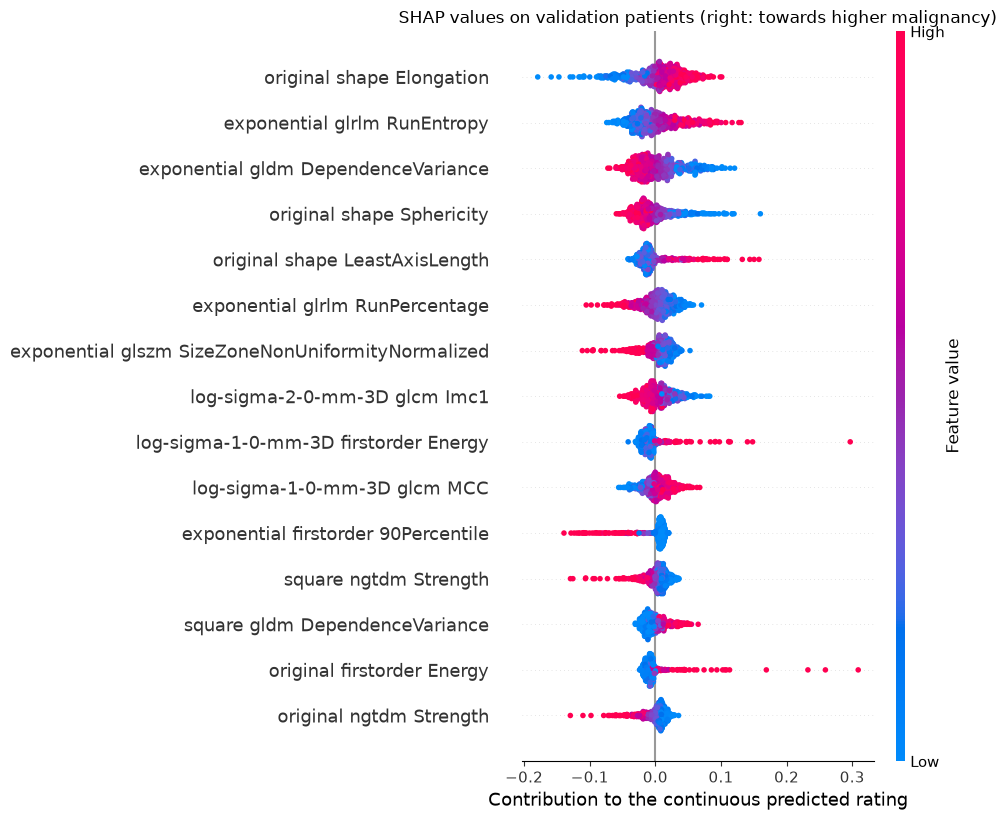

In [17]:
print(f"Average prediction (SHAP base value): {interpretation['shap_base_value']:.2f}")
display(interpretation["figures"]["shap"])

- **Forma e tamanho aumentam a previsão.** Valores altos do menor eixo e da energia de primeira ordem, ligados ao tamanho, empurram a previsão para cima, até cerca de 0,3 pontos nos nódulos maiores. Nódulos menos esféricos e com *Elongation* alta (que no PyRadiomics indica nódulos menos alongados) também recebem previsões mais altas; a *Elongation* é a característica com maior contribuição SHAP média em valor absoluto. Apesar disso, baralhar as características de forma quase não altera a QWK (0,007, ver acima). As duas medidas avaliam aspetos diferentes: o SHAP explica a previsão contínua, enquanto a permutação mede a perda de QWK após os cortes; a redundância com outras características também pode limitar essa perda.
- **Densidade muito alta diminui a previsão.** Valores altos do percentil 90 e da percentagem de *runs* após o filtro exponencial, que realça as densidades mais elevadas, baixam a previsão até cerca de 0,15 pontos. Este padrão é compatível com as previsões mais baixas nos nódulos calcificados observadas acima, mas não demonstra que o modelo reconheça a calcificação.
- **As contribuições individuais são pequenas.** Com 193 características correlacionadas, o crédito fica repartido e as maiores contribuições individuais mostradas no gráfico são da ordem de 0,35 pontos.

### Tamanho, previsão e pontos de corte

Esta figura liga a interpretação à auditoria de equidade: mostra a previsão contínua de cada nódulo de validação em função do diâmetro, com os pontos de corte validados.

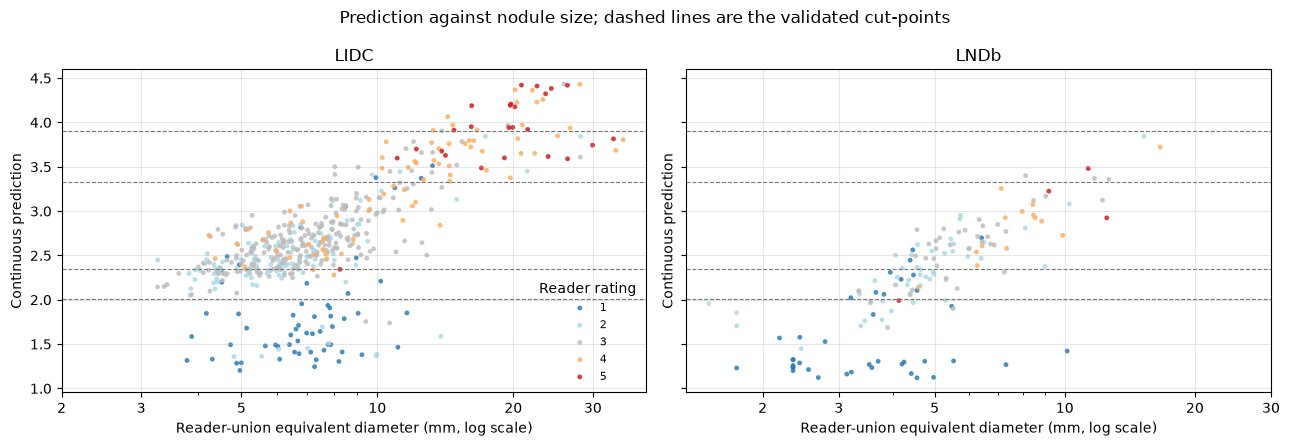

In [18]:
display(interpretation["figures"]["diameter"])

- **A previsão cresce com o diâmetro**, e os nódulos de classificação 1 formam um grupo separado em baixo, quase independente do tamanho, que corresponde sobretudo aos nódulos calcificados.
- **Os nódulos pequenos de alto risco ficam abaixo do ponto de corte.** Entre 6 e 10 mm, os nódulos com classificação 4 ou 5 aparecem acima dos de classificação 1, mas nenhum ultrapassa o ponto de corte da classe 4 (3,33). Este padrão é coerente com a auditoria de equidade e com o menor tamanho dos nódulos suspeitos do LNDb, mas o gráfico não permite atribuir causalmente os erros ao tamanho.

**Limitações.** As explicações descrevem associações aprendidas pelo modelo, não causalidade. O SHAP substitui cada característica de forma independente, o que pode criar combinações pouco realistas entre características correlacionadas, pelo que os resultados por grupo são mais fiáveis do que a ordem individual. Os resultados referem-se a uma única partição de validação e a classificações de leitores, não a diagnósticos confirmados.

## Proposta final: triagem em 3 classes (*human-in-the-loop* e avaliação nos extremos)

### Síntese técnica da pipeline

Depois das experiências nas partições holdout de pacientes (`fitting`, `threshold` e `selection`), a proposta usa a seguinte configuração:

- **Pré-processamento e redução de dimensionalidade:**
  - Imputação dos valores em falta pela mediana da partição de ajuste.
  - Filtro de correlação de Pearson: remove constantes e características com $|r| > 0,85$ face a alguma característica já retida.
  - Seleção por informação mútua (`SelectKBest`) com **$K = 200$**, o que, neste ajuste, equivale a não remover nenhuma das 193 características retidas pelo filtro de correlação: embora $K = 50$ tenha obtido uma QWK de seleção ligeiramente superior (0,6714 contra 0,6637), $K = 200$ teve a maior exatidão (**0,5835**), o maior F1 macro (**0,5335**) e o menor MAE (**0,4965**).
  - Normalização por `StandardScaler`, ajustada apenas nos dados de treino de cada modelo.
  - PCA com **95% da variância explicada**, para reduzir a dimensionalidade e a correlação residual.
- **Hiperparâmetros do Random Forest:** a experiência com hiperparâmetros escolheu, para o modelo de 5 classes, 750 árvores, profundidade máxima 10 e folhas com pelo menos 10 nódulos (`SELECTED_FIT_SETTINGS`; QWK de seleção de 5 classes de **0,6690**, contra **0,6637** com a configuração base). Na triagem, os dois conjuntos voltam a ser comparados nos pacientes de seleção, com os limiares orientados pela sensibilidade descritos abaixo: ambos identificam 11 dos 18 nódulos de classe 3 (sensibilidade **0,611**), e a configuração escolhida coloca menos nódulos na classe indeterminada (**72,9%** contra **74,1%**). Pela regra de desempate, usa-se `SELECTED_FIT_SETTINGS`:
  - `n_estimators = 750`, `max_depth = 10` e `min_samples_leaf = 10`.
  - `max_features = 0.3` e `lndb_weight = 4.0`, que multiplica por 4 os pesos de amostra do LNDb, além dos pesos equilibrados por classificação. Este multiplicador não garante igual peso total aos dois conjuntos.
- **Pontos de corte orientados pela triagem:** os 2 pontos de corte ($t_1, t_2$) são definidos nos pacientes de limiares. O corte $t_2$ (classe 2|3) é o ponto médio entre previsões consecutivas mais alto que mantém pelo menos **80%** dos nódulos de classe 3 da partição de limiares acima dele; com $t_2$ fixo, $t_1$ (classe 1|2) é o corte que maximiza a QWK, testando todos os pontos médios entre previsões consecutivas, e em caso de empate fica o corte mais baixo, que coloca menos nódulos na classe de baixo risco. Os limiares do protocolo principal, que maximizam apenas a QWK, deixavam a maioria dos nódulos de alto risco na classe indeterminada.

---

### Compreensão do problema (*business understanding*): porquê 3 classes

A passagem de um classificador de 5 classes para um modelo de triagem em 3 classes centrado nos extremos é uma mudança do objetivo de avaliação, motivada por uma possível utilização clínica que este estudo não valida.

**Porquê focar nos extremos e manter o radiologista no circuito (*human-in-the-loop*)?**

As classificações dos leitores apresentam desacordo, documentado no notebook 01. Distinguir classificações próximas pode refletir parte dessa variabilidade; agrupá-las reduz a granularidade exigida, mas também perde informação e não elimina o desacordo. Os resultados dos modelos de 5 classes deste notebook e do notebook 05 não demonstram segurança ou utilidade clínica.

Ao agrupar as classificações intermédias numa **classe 2 (indeterminado)** e separar os extremos (**classe 1: baixo risco** e **classe 3: alto risco**), explora-se uma proposta de triagem. As eventuais vantagens económicas e de carga de trabalho são hipóteses, não resultados medidos neste estudo:

1. **Apoio à priorização:** num eventual fluxo clínico, a classe 3 poderia sugerir revisão prioritária e a classe 1 uma prioridade menor, sempre com confirmação por um radiologista e integração da história clínica e de exames anteriores. Esta hipótese de organização do trabalho foi discutida em comunicação pessoal com Lucibel Carvalhais, Serviço de Oncologia, Hospital Baixo Vouga; não foi testada neste projeto.

2. **Segurança e *human-in-the-loop*:** no fluxo proposto, os casos indeterminados (classe 2) exigiriam avaliação detalhada por um radiologista, mantendo-se também a confirmação dos extremos. A supervisão humana não elimina os falsos negativos: na validação, parte dos nódulos colocados na classe 1 pertence a outras classes e 6 dos 29 nódulos de classe 3 não são identificados (ver resultados abaixo). As classes de referência são classificações de radiologistas, não diagnósticos confirmados.

3. **Enquadramento regulamentar:** uma eventual aplicação clínica exigiria definir a finalidade prevista e qualificar o *software* no MDR. Para informação usada em decisões de diagnóstico ou terapêutica, a regra 11 prevê classe IIa, IIb ou III consoante o impacto possível dessas decisões. Estas classes exigem avaliação da conformidade com organismo notificado; a presença do radiologista não determina, por si só, a classe. Não se atribui uma classe regulamentar a este protótipo académico. Fontes: [MDR, artigos 2.º e 52.º e anexo VIII, regra 11](https://eur-lex.europa.eu/eli/reg/2017/745/oj/por) e [MDCG 2019-11 rev.1, junho de 2025](https://health.ec.europa.eu/latest-updates/update-mdcg-2019-11-rev1-qualification-and-classification-software-regulation-eu-2017745-and-2025-06-17_en).

   Se uma futura aplicação cumprir as condições do artigo 6.º, n.º 1, e anexo I do Regulamento da IA, será enquadrada como IA de risco elevado, com requisitos de supervisão humana (artigo 14.º). Deve distinguir-se esse enquadramento do calendário de aplicação: na versão consolidada consultada em 18 de outubro de 2026, estas regras aplicam-se a essa categoria a partir de 2 de agosto de 2028 (artigo 113.º). Fonte: [Regulamento da IA, versão consolidada](https://eur-lex.europa.eu/eli/reg/2024/1689/2026-07-27/eng).


### Classes de triagem e partições

As classes de triagem partem do mesmo rótulo inteiro do modelo de 5 classes, `floor(média + 0,5)`: a classe 1 (baixo risco) corresponde à classificação 1, a classe 2 (indeterminado, requer radiologista) às classificações 2 a 4 e a classe 3 (alto risco) à classificação 5. O código desta secção está em `lung_project/triage.py`; usam-se as mesmas partições de pacientes do protocolo principal. As designações baixo e alto risco são abreviaturas destas classificações dos leitores, não estimativas de risco clínico. O campo `referred_to_radiologist` mede apenas a fração prevista na classe 2; as classes 1 e 3 também exigiriam confirmação por um radiologista num eventual uso clínico.

In [19]:
import numpy as np
from lung_project.evaluation import holdout_partitions
from lung_project.triage import (
    CLASS_3_TARGET_RECALL,
    plot_class_balance,
    plot_surrogate_tree,
    plot_triage_confusion,
    plot_triage_roc,
    rating_breakdown,
    refit_triage,
    save_triage,
    select_triage,
    surrogate_tree,
    triage_report,
    triage_subgroups,
    validate_triage,
)

# Classes de triagem a partir do rótulo inteiro floor(média + 0,5), em lung_project/triage.py:
# 1 = baixo risco (classificação 1), 2 = indeterminado (2 a 4, requer radiologista),
# 3 = alto risco (classificação 5).
triage_partitions, triage_final_pool = holdout_partitions(
    training, shared_split, final_cohort=training
)
TRIAGE_DIR = RUN_DIR / "triage"
TRIAGE_DIR.mkdir(exist_ok=False)

### Escolha da configuração de triagem nos pacientes de seleção

Nesta proposta de triagem, procura-se identificar os nódulos de classe 3 e reduzir a fração colocada na classe indeterminada. A QWK pesa todas as confusões entre classes e não mede diretamente este objetivo; com os limiares que a maximizam, a maioria dos nódulos de classe 3 ficava na classe indeterminada. Por isso, os limiares de triagem seguem uma regra própria, aplicada nos pacientes de limiares:

- **Corte 2|3:** ordenam-se as previsões dos nódulos de classe 3 e retém-se o número necessário para atingir pelo menos 80% (`CLASS_3_TARGET_RECALL`). O corte fica a meio entre a menor previsão ainda necessária e a previsão imediatamente inferior, de qualquer classe. Com 21 nódulos de classe 3 nesta partição, são necessários pelo menos 17 (81%); cada nódulo vale cerca de 5 pontos percentuais. Esta regra garante a meta na calibração, não nas outras partições.
- **Corte 1|2:** com o corte 2|3 fixo, o corte que maximiza a QWK; em caso de empate, fica o corte mais baixo, que coloca menos nódulos na classe de baixo risco.

Comparam-se nos pacientes de seleção os hiperparâmetros base (`FIT_SETTINGS`) e os escolhidos na experiência com hiperparâmetros (`SELECTED_FIT_SETTINGS`), ambos com estes limiares (`sensitivity`). Escolhe-se a configuração com maior sensibilidade agregada da classe 3 e, em caso de empate, a que coloca menos nódulos na classe indeterminada; só essa é avaliada na validação. As linhas `calibrated`, com os dois cortes otimizados apenas pela QWK como no protocolo principal, são apresentadas como referência e não podem ser escolhidas.

A decisão de passar para a triagem em 3 classes foi tomada depois de observar os resultados de validação do modelo de 5 classes; por isso, esta validação não é totalmente independente dessa decisão, embora os hiperparâmetros, os limiares e a estratégia sejam escolhidos sem os pacientes de validação. O agrupamento 1 / 2-4 / 5 é uma escolha de desenho motivada pela proposta de triagem: não é comparado por QWK com a variável-alvo de 5 classes, porque os valores de QWK não são comparáveis entre definições diferentes da variável-alvo. Também não coincide com os agrupamentos de 3 classes das experiências com variáveis-alvo alternativas, que treinam diretamente com o rótulo agrupado; aqui, o regressor continua a aprender a média dos leitores na escala de 1 a 5, e só os pontos de corte definem as 3 classes.

In [20]:
triage = select_triage(
    triage_partitions,
    feature_columns,
    {"FIT_SETTINGS": FIT_SETTINGS, "SELECTED_FIT_SETTINGS": SELECTED_FIT_SETTINGS},
    seed=SEED,
)
display(triage["selection_metrics"].round(4))
print(
    f"Configuração escolhida na seleção: {triage['settings_name']}, "
    f"limiares {triage['strategy']} {np.round(triage['validated_thresholds'], 4)} "
    f"(objetivo de sensibilidade da classe 3: {CLASS_3_TARGET_RECALL:.0%}), "
    f"sensibilidade da classe 3 na seleção {triage['selection_recall_class_3']:.4f}, "
    f"encaminhados {triage['selection_referred']:.4f}"
)

,settings,strategy,thresholds,nodules,qwk,balanced_accuracy,recall_class_1,recall_class_3,referred_to_radiologist
0,FIT_SETTINGS,calibrated,"[2.0303, 4.1777]",425,0.6335,0.6835,0.7460,0.3889,0.8047
1,FIT_SETTINGS,sensitivity,"[1.9855, 3.5646]",425,0.5663,0.7310,0.7302,0.6111,0.7412
2,SELECTED_FIT_SETTINGS,calibrated,"[2.0032, 4.0583]",425,0.6329,0.6958,0.7302,0.4444,0.8024
3,SELECTED_FIT_SETTINGS,sensitivity,"[2.0184, 3.5386]",425,0.5634,0.7324,0.7460,0.6111,0.7294


Configuração escolhida na seleção: SELECTED_FIT_SETTINGS, limiares sensitivity [2.0184 3.5386] (objetivo de sensibilidade da classe 3: 80%), sensibilidade da classe 3 na seleção 0.6111, encaminhados 0.7294


### Avaliação na validação

Na seleção, as duas configurações identificam 11 dos 18 nódulos de classe 3 (**0,611**), abaixo do objetivo de 80% fixado nos pacientes de limiares, o que mostra a incerteza com tão poucos nódulos; com os cortes otimizados pela QWK, a sensibilidade era de 0,39 a 0,44. Escolhe-se `SELECTED_FIT_SETTINGS`, que coloca menos nódulos na classe indeterminada (72,9% contra 74,1%). Como é a configuração do modelo de 5 classes, ajustada nos mesmos pacientes e com a mesma semente, o modelo de triagem validado produz as mesmas previsões contínuas que o modelo de 5 classes validado; só os pontos de corte diferem.

A configuração escolhida prevê os pacientes de validação uma única vez. Apresentam-se as métricas agregadas e por conjunto de dados, o relatório de classificação, a distribuição das classes previstas por classificação original dos leitores (1 a 5) e a matriz de confusão.

Configuração da triagem: {'info_gain_k': 200, 'n_estimators': 750, 'max_depth': 10, 'min_samples_leaf': 10, 'max_features': 0.3}


,dataset,nodules,qwk,balanced_accuracy,recall_class_1,recall_class_3,referred_to_radiologist
0,pooled,655,0.6400,0.8045,0.7526,0.7931,0.7450
1,lidc,512,0.6622,0.8517,0.7586,0.9200,0.7656
2,lndb,143,0.5069,0.5245,0.7436,0.0000,0.6713


                                  precision    recall  f1-score   support

                 1 - Baixo risco       0.73      0.75      0.74        97
2 - Indeterminado (radiologista)       0.94      0.87      0.90       529
                  3 - Alto risco       0.34      0.79      0.48        29

                        accuracy                           0.85       655
                       macro avg       0.67      0.80      0.71       655
                    weighted avg       0.88      0.85      0.86       655

Nódulos de validação por classificação dos leitores (1 a 5) e classe de triagem prevista:


predicted triage class,1,2,3
reader rating,,,
1,73,24,0
2,21,142,3
3,5,261,9
4,0,56,32
5,1,5,23


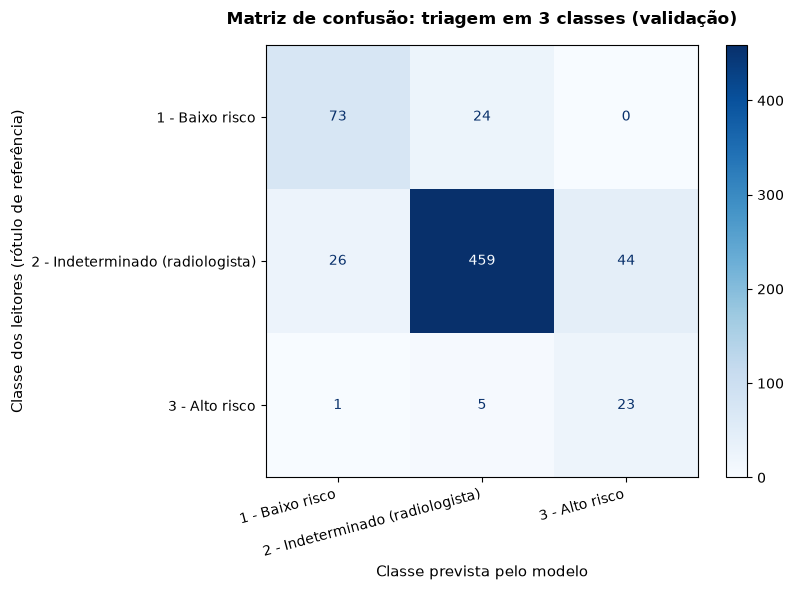

In [21]:
triage_validation, triage_validation_metrics = validate_triage(
    triage, triage_partitions["validation"]
)
settings = triage["fit_settings"]
print(
    "Configuração da triagem:",
    {key: settings[key] for key in ("info_gain_k", "n_estimators", "max_depth", "min_samples_leaf", "max_features")},
)
display(triage_validation_metrics.round(4))
print(triage_report(triage_validation))
print("Nódulos de validação por classificação dos leitores (1 a 5) e classe de triagem prevista:")
display(rating_breakdown(triage_validation))
plot_triage_confusion(triage_validation)

### Leitura da validação da triagem

- **A sensibilidade da classe 3 aproxima-se do objetivo.** O modelo identifica 23 dos 29 nódulos de classe 3 (**0,79**): 23 de 25 no LIDC (**0,92**) e nenhum dos 4 do LNDb. Na seleção, os cortes otimizados apenas pela QWK identificavam 0,39 a 0,44 dos nódulos de classe 3, contra 0,61 com esta regra, apesar de uma QWK de seleção mais alta (cerca de 0,63 contra 0,56). A QWK não mede diretamente este objetivo. Como referido acima, a reformulação para triagem ocorreu após observar a validação de 5 classes, pelo que estes resultados continuam a ser exploratórios.
- **Os falsos positivos da classe 3 são sobretudo nódulos de classificação 4.** Dos 67 nódulos colocados na classe 3, 44 não têm classificação 5 (precisão 0,34), mas 32 destes têm classificação 4 (moderadamente suspeitos), 9 têm 3 e apenas 3 têm 2. A classe 3 destina-se a sugerir revisão prioritária por um radiologista. Os custos clínicos e operacionais destes falsos positivos e das omissões não foram medidos.
- **Quase nenhum nódulo de alto risco é colocado na classe 1.** Dos 100 nódulos colocados na classe 1, 73 têm classificação 1, 21 têm 2 e 5 têm 3; nenhum tem classificação 4 e apenas um tem 5 (`LNDb-0053_finding2`, previsão contínua 1,99). Esta é a maior subestimação da classificação dos leitores nesta validação.
- **Fração indeterminada.** O modelo coloca 74,5% dos nódulos na classe 2 e atribui um extremo a cerca de 25% (100 na classe 1 e 67 na classe 3). Estes valores não medem uma redução da carga de trabalho: as classes extremas também exigiriam revisão e não foi avaliado um fluxo clínico. A exatidão (0,85) é superior à de um classificador que prevê sempre a classe 2 (0,81: 529 dos 655 nódulos de validação são de classe 2), mas a diferença relevante está na sensibilidade da classe 3, que nesse classificador é 0.

### Equidade da triagem por subgrupo

Repete-se, de forma descritiva, a parte central da auditoria de equidade para o modelo de triagem, nos mesmos pacientes de validação e sem novo ajuste. Comparam-se o conjunto de dados e o tamanho do nódulo, as duas fontes de diferença encontradas no modelo de 5 classes. Com `high_rating=3`, `high_rated`, `high_detected` e `high_recall` referem-se à classe 3; `class1_rated` e `class1_detected` são o equivalente para a classe 1, e `referred_to_radiologist` é a fração de nódulos colocados na classe 2. `false_high` é o número de nódulos colocados na classe 3 sem classificação 5 (falsos positivos da classe 3); ao contrário de `false_high_rate` na auditoria de 5 classes, é uma contagem e não uma fração. As taxas ficam em falta quando o denominador tem menos de 5 nódulos, e não se calculam intervalos, porque há poucos nódulos de classe 3.

In [22]:
triage_subgroup_table = triage_subgroups(triage_validation, training)
display(triage_subgroup_table.round(3))

,attribute,group,nodules,patients,qwk,high_rated,high_detected,high_recall,false_high,class1_rated,class1_detected,referred_to_radiologist
0,dataset,lidc,512,169,0.662,25,23,0.92,42,58,44,0.766
1,dataset,lndb,143,41,0.507,4,0,NaN,2,39,29,0.671
2,size_band,10-20 mm,93,71,0.402,15,12,0.80,27,7,3,0.527
3,size_band,6-10 mm,283,140,0.766,2,0,NaN,0,38,31,0.866
4,size_band,<6 mm,250,110,0.608,1,0,NaN,0,52,39,0.772
5,size_band,>=20 mm,29,25,0.043,11,11,1.00,17,0,0,0.034


- **A identificação da classe 3 varia com o tamanho.** Os 23 nódulos de classe 3 identificados são todos do LIDC e têm pelo menos 10 mm (12 de 15 entre 10 e 20 mm; 11 de 11 com 20 mm ou mais). Nenhum dos 3 nódulos de classe 3 com menos de 10 mm nem dos 4 do LNDb é identificado.
- **Os falsos positivos da classe 3 também são nódulos grandes.** Os 44 nódulos colocados na classe 3 sem classificação 5 têm todos pelo menos 10 mm (27 entre 10 e 20 mm e 17 com 20 mm ou mais), e 42 são do LIDC. Na prática, quase todos os nódulos com 20 mm ou mais são colocados na classe 3 (28 de 29), o que explica a QWK de 0,04 nesse grupo.
- **A classe 1 é identificada de forma semelhante nos dois conjuntos de dados:** 44 de 58 no LIDC (76%) e 29 de 39 no LNDb (74%), e 75% a 82% nos nódulos com menos de 10 mm.
- **O LNDb tem menor fração indeterminada** (67% contra 77%), num conjunto com proporcionalmente mais nódulos de classe 1 (27% contra 11%); o modelo coloca apenas 2 nódulos do LNDb na classe 3, ambos sem classificação 5.
- **Limitações.** Os grupos de classe 3 são muito pequenos, pelo que estas diferenças são descritivas e não têm intervalos de confiança. A QWK por grupo é instável nos grupos pequenos.

### Curvas ROC da previsão contínua

Avalia-se a previsão contínua, antes dos pontos de corte, em duas decisões: separar a classe 3 das restantes e separar as classes 2 e 3 da classe 1.

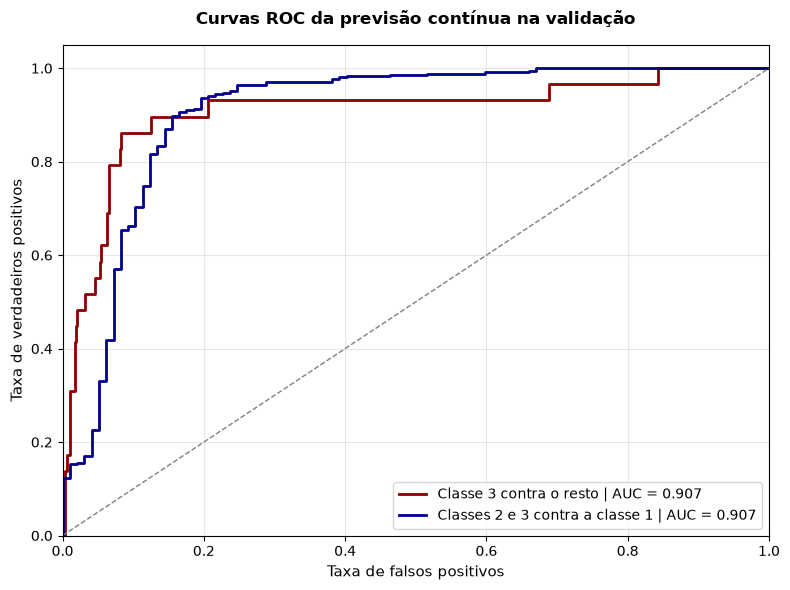

AUC na validação: {'class_3_vs_rest': 0.907, 'classes_2_3_vs_class_1': 0.907}


In [23]:
triage_roc_auc = plot_triage_roc(triage_validation)
print("AUC na validação:", {name: round(value, 3) for name, value in triage_roc_auc.items()})

- **A previsão contínua ordena bem os nódulos nas duas decisões** (as duas AUC arredondam para **0,907**, embora correspondam a decisões diferentes). Os pontos de corte fixam o compromisso observado entre a sensibilidade da classe 3 e a fração indeterminada; a AUC, por si só, não valida esses cortes nem demonstra utilidade clínica.
- **A AUC é agregada e dominada pelo LIDC.** Não mostra as falhas por subgrupo descritas acima: nenhum dos 4 nódulos de classe 3 do LNDb e nenhum dos 3 com menos de 10 mm é identificado.

### Reajuste do modelo final e registo

Como no protocolo principal, o modelo final é ajustado em todos os pacientes exceto os de limiares, e os pontos de corte voltam a ser definidos nesses pacientes com a mesma regra (corte 2|3 para 80% de sensibilidade da classe 3, corte 1|2 pela QWK), usando as previsões do modelo final. Nesta execução, o corte 2|3 passa de 3,54 no modelo validado para 3,98 no modelo final: as previsões do modelo final para os nódulos de classe 3 dos pacientes de limiares são mais altas, pelo que o corte que mantém 80% destes nódulos acima dele também sobe. Como no modelo de 5 classes, estes limiares finais não têm verificação independente. Guardam-se em `triage/`, no diretório da experiência, os dois modelos, os limiares, o objetivo de sensibilidade, as tabelas de seleção, validação e subgrupos e um resumo.

In [24]:
triage_final_model, triage_final_thresholds = refit_triage(
    triage, triage_final_pool, triage_partitions["threshold"], feature_columns, seed=SEED
)
save_triage(
    TRIAGE_DIR,
    triage,
    triage_final_model,
    triage_final_thresholds,
    results={
        "selection_metrics": triage["selection_metrics"],
        "validation_predictions": triage_validation,
        "validation_metrics": triage_validation_metrics,
        "subgroups": triage_subgroup_table,
        "summary": {
            "validation_metrics": triage_validation_metrics.to_dict(orient="records"),
            "validation_roc_auc": triage_roc_auc,
            "final_training_patients": int(triage_final_pool.patient_id.nunique()),
        },
    },
)
print("Limiares finais do modelo reajustado:", np.round(triage_final_thresholds, 4))
print("Resultados da triagem guardados em:", TRIAGE_DIR.relative_to(PROJECT_ROOT))

Limiares finais do modelo reajustado: [2.0482 3.9845]
Resultados da triagem guardados em: outputs/experiments/radiomics_contours_holdout_152f8584d339_20261018T170722864282Z_meantarget_weightlndb_4/triage


### Árvore simplificada para leitura das variáveis usadas na triagem

O Random Forest decide sobre componentes PCA, que são combinações de características radiómicas. Esta árvore é um resumo aproximado do modelo: usa 8 características radiómicas originais, escolhidas pela importância das componentes repartida pelos seus pesos, e tenta reproduzir as classes previstas pelo Random Forest. Não é uma árvore interna do Random Forest nem deve ser usada isoladamente para decisões.

Variáveis radiómicas selecionadas para a árvore simplificada:


,variable,radiomics_feature,importance_share
0,exponential / textura GLDM / DependenceVariance,exponential_gldm_DependenceVariance,0.0068
1,square / textura NGTDM / Strength,square_ngtdm_Strength,0.0067
2,exponential / textura GLRLM / RunEntropy,exponential_glrlm_RunEntropy,0.0067
3,logarithm / textura GLSZM / ZoneEntropy,logarithm_glszm_ZoneEntropy,0.0067
4,original / textura NGTDM / Strength,original_ngtdm_Strength,0.0066
5,original / textura NGTDM / Coarseness,original_ngtdm_Coarseness,0.0066
6,original / textura GLSZM / SmallAreaLowGrayLev...,original_glszm_SmallAreaLowGrayLevelEmphasis,0.0066
7,log-sigma-1-0-mm-3D / intensidade / Maximum,log-sigma-1-0-mm-3D_firstorder_Maximum,0.0066


A árvore reproduz 86.2% das previsões do Random Forest neste conjunto de referência. Esta fidelidade é descritiva e foi medida nos mesmos dados usados para ajustar a árvore.


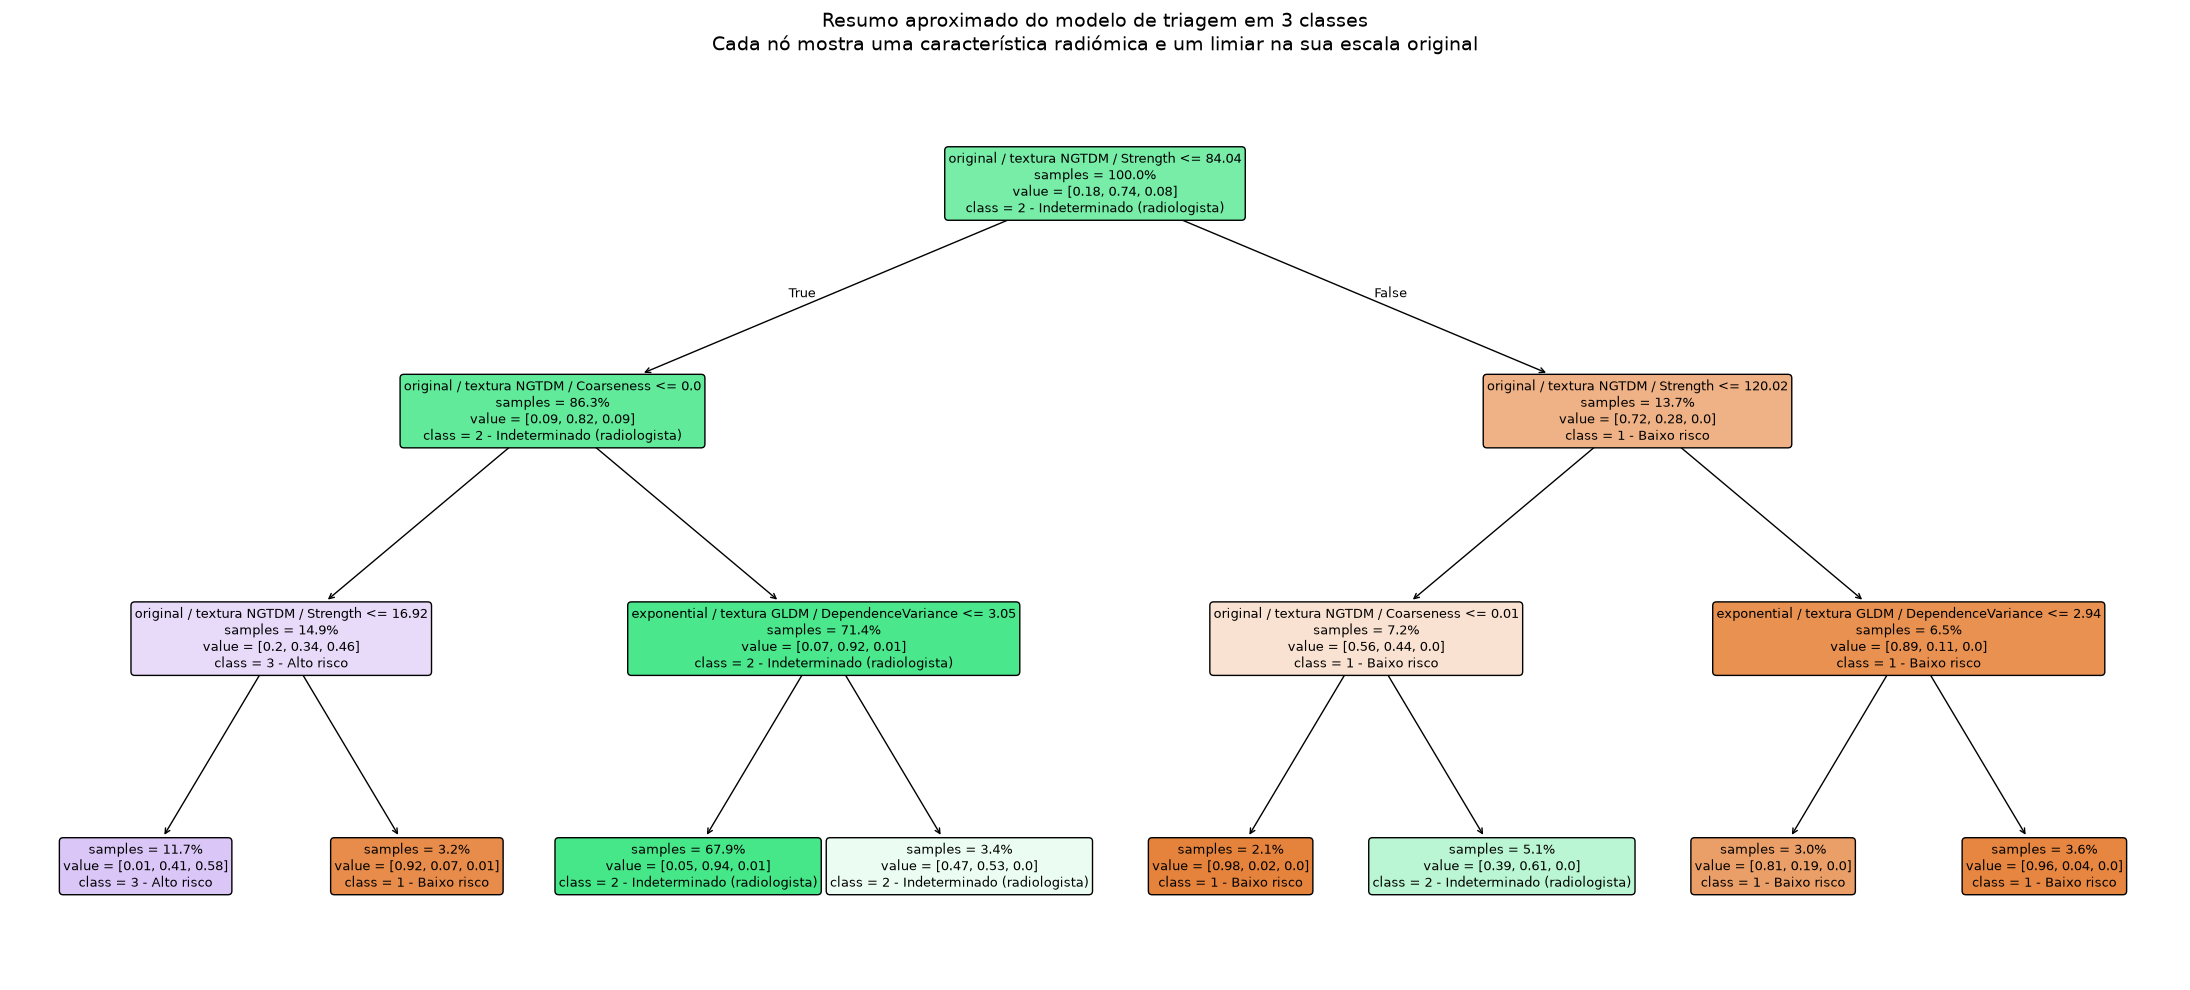

In [25]:
surrogate = surrogate_tree(
    triage_final_model, triage_final_pool, triage_final_thresholds, seed=SEED
)
print("Variáveis radiómicas selecionadas para a árvore simplificada:")
display(surrogate["features"].round({"importance_share": 4}))
print(
    f"A árvore reproduz {surrogate['fidelity']:.1%} das previsões do Random Forest "
    "neste conjunto de referência. Esta fidelidade é descritiva e foi medida "
    "nos mesmos dados usados para ajustar a árvore."
)
plot_surrogate_tree(surrogate)

As quotas de importância das 8 variáveis são muito próximas (0,66% a 0,68%, contra 0,50% se a importância fosse uniforme pelas 199 características retidas pelo filtro de correlação no modelo final), pelo que estas variáveis não são claramente mais importantes do que as restantes: a importância das componentes PCA reparte-se por muitas características. A árvore deve ser lida como uma ilustração de regras aproximadas, não como a lista das variáveis decisivas; para isso, a referência são as secções de interpretabilidade acima (grupos baralhados e SHAP).

### Experiência: desequilíbrio de classes

Compara-se a distribuição das classificações de 1 a 5 por conjunto de dados com a das 3 classes de triagem, na coorte de modelação e com as mesmas classes do modelo. Um classificador ingénuo que prevê sempre a classe 2 mostra porque é que a exatidão, sozinha, esconde os nódulos de alto risco ignorados.

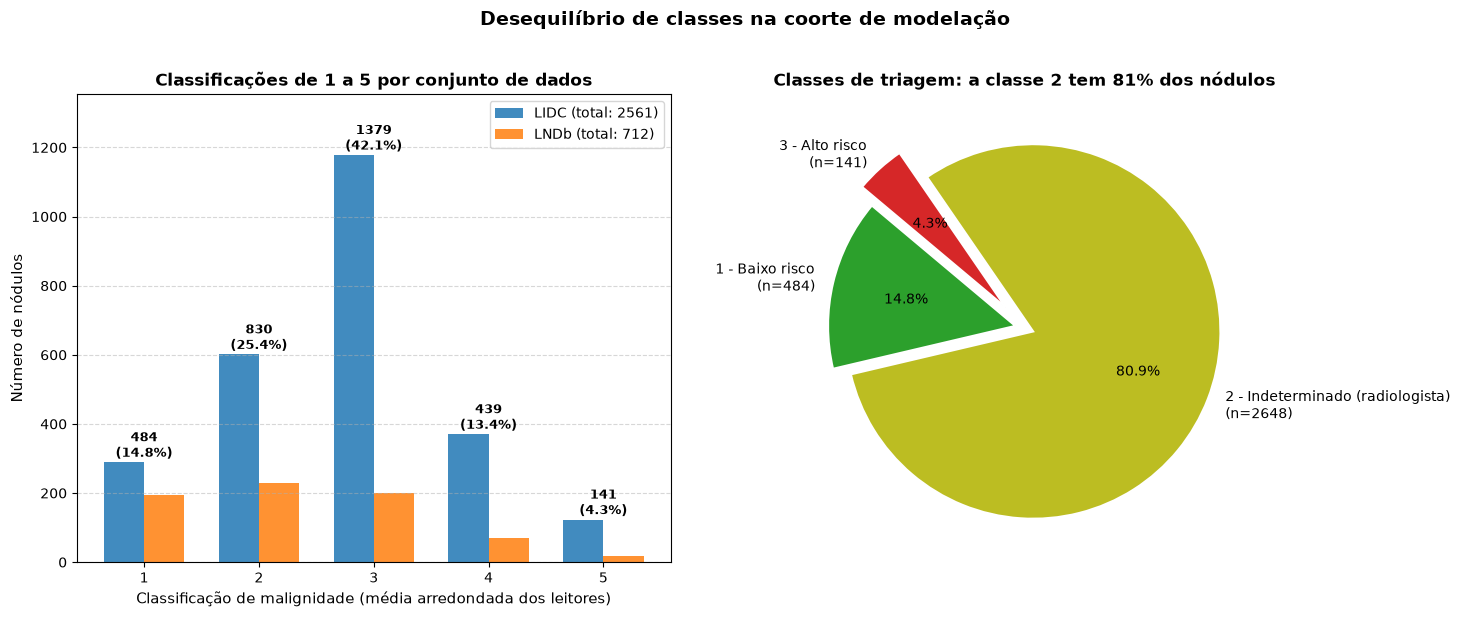

EXPERIÊNCIA: O IMPACTO DO DESEQUILÍBRIO NUM CLASSIFICADOR INGÉNUO
1. Exatidão do classificador ingénuo (sempre classe 2): 80.90%
2. Sensibilidade (recall) para os nódulos de alto risco (classe 3): 0.00%
3. Conclusão: todos os nódulos de alto risco são ignorados, apesar de uma exatidão de 80.9%.


In [26]:
class_balance = plot_class_balance(training)
print("=" * 70)
print("EXPERIÊNCIA: O IMPACTO DO DESEQUILÍBRIO NUM CLASSIFICADOR INGÉNUO")
print("=" * 70)
print(
    "1. Exatidão do classificador ingénuo (sempre classe 2): "
    f"{class_balance['naive_accuracy']:.2%}"
)
print(
    "2. Sensibilidade (recall) para os nódulos de alto risco (classe 3): "
    f"{class_balance['naive_recall_class_3']:.2%}"
)
print(
    "3. Conclusão: todos os nódulos de alto risco são ignorados, apesar de uma "
    f"exatidão de {class_balance['naive_accuracy']:.1%}."
)
print("=" * 70)